# 🌪️ 00. Saudi Arabia NWP: Comprehensive Data Science Visualization & Distribution Masterclass
### *Extended-Range Sand & Dust Storm Forecasting | Exploratory Data Science, Cumulative Accumulations & Distribution Modeling*

---

## 📌 Executive Overview & Notebook Purpose
This notebook serves as the **comprehensive exploratory visualization and statistical distribution masterclass** for the Saudi Arabian Numerical Weather Prediction (NWP) dataset derived from the **Copernicus Atmosphere Monitoring Service (CAMS)** and the engineered physics feature pipeline.

### 🎯 Key Visualization & Analytical Dimensions:
1. **Univariate Distributions & Statistical Density:**
   - Histograms with Kernel Density Estimation (KDE) across raw and log-transformed scales.
   - Dispersion analysis using Box Plots, Violin Plots, and Outlier Whiskers.
   - Quantile-Quantile (Q-Q) and Probability plots testing against Normal, Lognormal, and Weibull distributions.
2. **Cumulative Distributions & Atmospheric Accumulations:**
   - Empirical Cumulative Distribution Functions (ECDF) across forecast cycles and lead times.
   - Cumulative mass fraction (Lorenz curve & Gini inequality coefficient) of atmospheric dust.
   - Spatial time-integrated cumulative dust exposure ($\int_{72h}^{120h} \text{PM}_{10}(t) dt$) over the Arabian Peninsula.
   - Cumulative Owen saltation flux ($\Sigma Q$) and kinetic energy accumulation curves.
3. **Bivariate & Joint Relationships:**
   - Massive-sample Hexbin 2D density plots and bivariate KDE contours solving overplotting.
   - Non-linear regression fits (LOWESS / polynomial) for wind shear, friction velocity, and surface concentration.
4. **Multivariate Analytics & Dimensionality Reduction:**
   - Full triangular correlation heatmaps (Pearson linear & Spearman monotonic rank).
   - Principal Component Analysis (PCA) biplots, 2D/3D state projections, and Scree variance curves.
5. **Polar & Directional Wind-Dust Dynamics:**
   - 16-sector Polar Wind Rose and Directional PM10 Dust Flux Rose highlighting Shamal wind corridors.
   - Multi-metric Radar / Spider charts contrasting Arabian desert ecoregions.
6. **Synoptic Geospatial Maps & Atmospheric Flows:**
   - 2D `pcolormesh` and filled contour (`contourf`) maps over Saudi Arabia with key reference cities.
   - Wind velocity vector quivers and streamlines superimposed on dust plumes.
   - Multi-lead small multiples tracking sandstorm propagation from Day 3 (72h) to Day 5 (120h).
7. **Categorical Hazard & Risk Distributions:**
   - Donut charts and stacked bar charts across WHO/WMO dust storm severity tiers.
   - Regional contingency heatmaps of wind intensity vs. sandstorm risk.
8. **Time-Series Evolution & Uncertainty Bounds:**
   - Forecast trajectory progression with median, Interquartile Range (IQR 25th-75th), and 95% confidence bands.
   - Tracking the spatial centroid (center of mass) of the dust cloud over lead times.


In [1]:
# ==============================================================================
# 0.0 Environment Setup, Scientific Imports & Publication Aesthetics
# ==============================================================================
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from IPython.display import display

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import seaborn as sns

# Suppress minor warnings for clean report generation
warnings.filterwarnings('ignore')

# Set publication aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 130
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 9.5
plt.rcParams['ytick.labelsize'] = 9.5
plt.rcParams['legend.fontsize'] = 9.5

# Define custom Arabian Sandstorm Palette
PALETTE_DUST = ['#E9D8A6', '#EE9B00', '#CA6702', '#BB3E03', '#AE2012', '#9B2226']
PALETTE_ACCENT = ['#1D3557', '#457B9D', '#A8DADC', '#F4A261', '#E76F51']
CMAP_DUST = 'copper_r'
CMAP_DENSITY = 'viridis'

print("✅ Visualization environment successfully initialized with publication parameters.")


✅ Visualization environment successfully initialized with publication parameters.


---
## 1.0 Multi-Modal Data Ingestion & Geometry Configuration
We ingest two complementary representations of the Saudi Arabian NWP data:
1. **4D NetCDF Spatial Dataset (`cams_forecast_saudi_arabia.nc`):** Preserves explicit coordinate geometry (`forecast_period`, `forecast_reference_time`, `latitude`, `longitude`).
2. **Engineered Feature Matrix (`saudi_nwp_engineered_features.parquet` / `.csv`):** Flattened tabular matrix containing 130,032 observations and 29 physical, kinetic, and geographic predictors.


In [2]:
# ==============================================================================
# 1.0 Data Ingestion & Geographic Reference Configuration
# ==============================================================================
# Resolve paths reliably whether executed from notebooks/ or workspace root
base_paths = [Path(".."), Path(".")]
nc_path = None
parquet_path = None

for bp in base_paths:
    candidate_nc = bp / "data" / "raw" / "nwp" / "cams_forecast_saudi_arabia.nc"
    candidate_pq = bp / "data" / "processed" / "saudi_nwp_engineered_features.parquet"
    if candidate_nc.exists() and nc_path is None:
        nc_path = candidate_nc
    if candidate_pq.exists() and parquet_path is None:
        parquet_path = candidate_pq

print(f"📦 NetCDF Spatial Dataset  : {nc_path.resolve()}")
print(f"📦 Engineered Feature Table : {parquet_path.resolve()}")

# Load xarray Dataset
ds = xr.open_dataset(nc_path)

# Load tabular features
df = pd.read_parquet(parquet_path)

# Ensure valid datetime formats
df['valid_time'] = pd.to_datetime(df['valid_time'])
df['ref_time'] = pd.to_datetime(df['ref_time'])

# Define key Saudi reference points for localized atmospheric inspection
CITIES = {
    'Riyadh': {'lat': 24.71, 'lon': 46.68, 'marker': 'o', 'color': '#D90429'},
    'Jeddah / Western': {'lat': 21.54, 'lon': 39.17, 'marker': 's', 'color': '#0077B6'},
    'Dammam / Eastern': {'lat': 26.42, 'lon': 50.09, 'marker': '^', 'color': '#023E8A'},
    'Tabuk / Northwest': {'lat': 28.38, 'lon': 36.57, 'marker': 'd', 'color': '#2B9348'},
    'Rub al Khali Core': {'lat': 20.00, 'lon': 50.00, 'marker': '*', 'color': '#9B2226'},
    'An Nafud Core': {'lat': 28.00, 'lon': 41.00, 'marker': 'p', 'color': '#E85D04'}
}

# Add categorical hazard classification
def classify_hazard(pm10):
    if pm10 < 50:
        return 'Normal (<50)'
    elif pm10 < 150:
        return 'Moderate (50-150)'
    elif pm10 < 500:
        return 'Elevated Dust (150-500)'
    elif pm10 < 1500:
        return 'Severe Sandstorm (500-1500)'
    else:
        return 'Extreme Haboob (>1500)'

df['hazard_class'] = df['nwp_pm10_ugm3'].apply(classify_hazard)
hazard_order = ['Normal (<50)', 'Moderate (50-150)', 'Elevated Dust (150-500)', 'Severe Sandstorm (500-1500)', 'Extreme Haboob (>1500)']

print(f"✅ Ingested {len(df):,} tabular records across {len(df.columns)} features.")
print(f"✅ Grid dimensions: {len(ds.latitude)} lats x {len(ds.longitude)} lons | Leads: {len(ds.forecast_period)} | Cycles: {len(ds.forecast_reference_time)}")
df[['nwp_pm10_ugm3', 'nwp_aod550', 'wind_speed_10m', 'hazard_class']].head()


📦 NetCDF Spatial Dataset  : C:\Users\hp\Desktop\sandstorm_forecasting\data\raw\nwp\cams_forecast_saudi_arabia.nc
📦 Engineered Feature Table : C:\Users\hp\Desktop\sandstorm_forecasting\data\processed\saudi_nwp_engineered_features.parquet


✅ Ingested 130,032 tabular records across 30 features.
✅ Grid dimensions: 43 lats x 56 lons | Leads: 9 | Cycles: 6


,nwp_pm10_ugm3,nwp_aod550,wind_speed_10m,hazard_class
0,50.686100,0.039361,2.038674,Moderate (50-150)
1,49.325951,0.033931,1.210648,Normal (<50)
2,40.433937,0.030227,0.527321,Normal (<50)
3,37.535717,0.043146,0.357501,Normal (<50)
4,29.219524,0.060772,0.578639,Normal (<50)


---
## 2.0 Module 1: Univariate Distributions & Statistical Density
In atmospheric science and air pollution modeling, surface aerosol concentrations ($\text{PM}_{10}$) and optical depths ($\text{AOD}$) exhibit extreme positive skewness, spanning multiple orders of magnitude between calm days and massive saltating sandstorms.

Here we visualize:
1. **Linear vs. Log-Transformed Probability Densities (Histograms & KDEs)**
2. **Dispersion & Stratified Quantile Spread (Box & Violin Plots across Lead Times)**
3. **Quantile-Quantile (Q-Q) & Empirical Probability Plots (Normality and Heavy-Tail Fits)**
4. **Higher-Order Statistical Moments (Mean, Variance, Skewness, Kurtosis)**


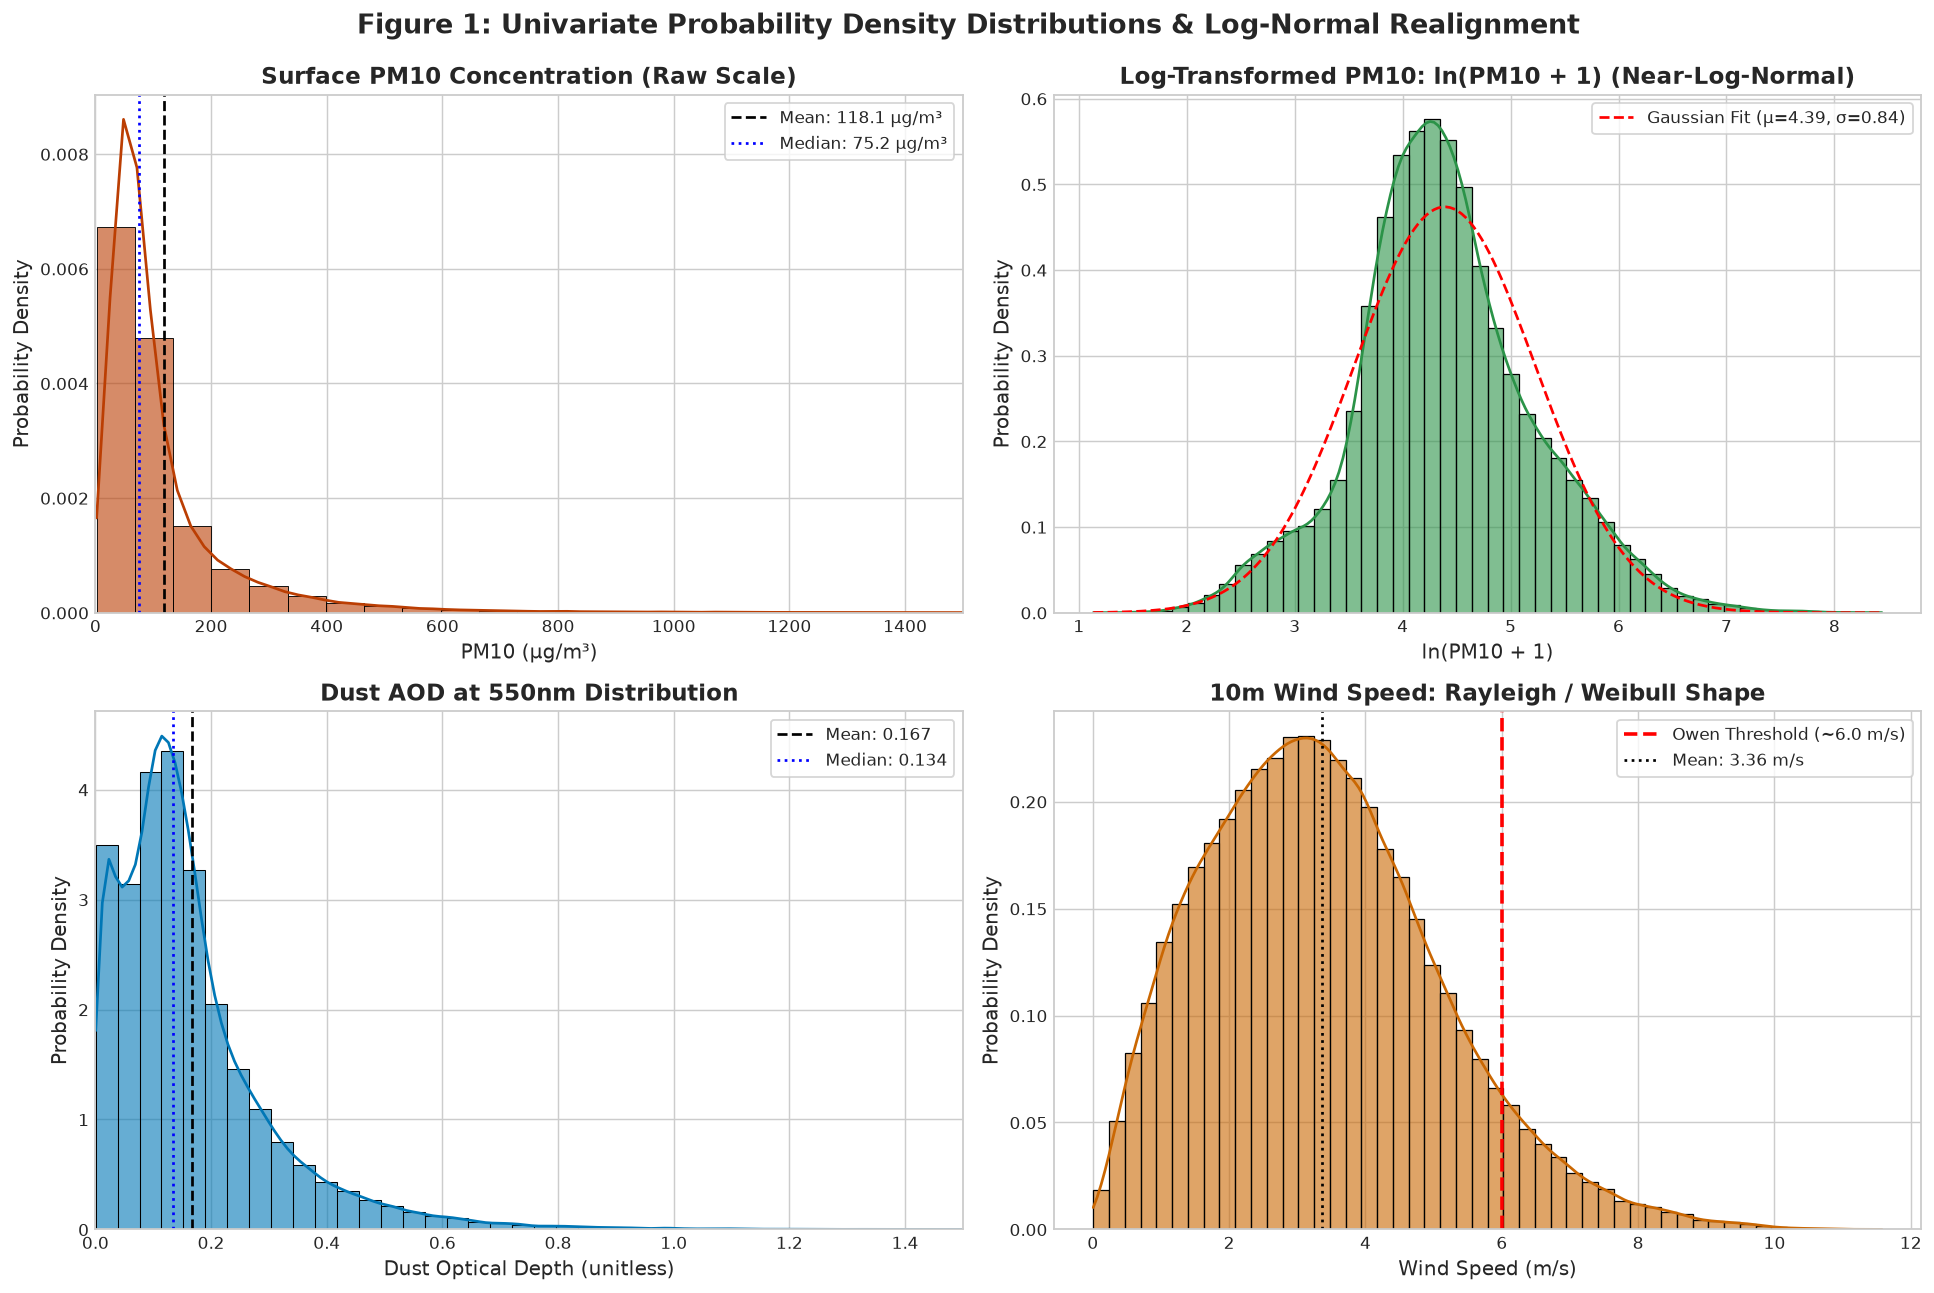

In [3]:
# ==============================================================================
# 2.1 Multi-Panel Histograms with Kernel Density Estimation (KDE)
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Raw PM10 Distribution
ax = axes[0, 0]
sns.histplot(df['nwp_pm10_ugm3'], kde=True, color='#BB3E03', bins=70, ax=ax, stat='density', alpha=0.6)
ax.axvline(df['nwp_pm10_ugm3'].mean(), color='black', linestyle='--', linewidth=1.5, label=f"Mean: {df['nwp_pm10_ugm3'].mean():.1f} μg/m³")
ax.axvline(df['nwp_pm10_ugm3'].median(), color='blue', linestyle=':', linewidth=1.5, label=f"Median: {df['nwp_pm10_ugm3'].median():.1f} μg/m³")
ax.set_title("Surface PM10 Concentration (Raw Scale)", fontweight='bold')
ax.set_xlabel("PM10 (μg/m³)")
ax.set_ylabel("Probability Density")
ax.set_xlim(0, 1500)
ax.legend(frameon=True)

# 2. Log-Transformed PM10 Distribution
ax = axes[0, 1]
sns.histplot(df['log_nwp_pm10'], kde=True, color='#2B9348', bins=50, ax=ax, stat='density', alpha=0.6)
mu, std = df['log_nwp_pm10'].mean(), df['log_nwp_pm10'].std()
x_norm = np.linspace(df['log_nwp_pm10'].min(), df['log_nwp_pm10'].max(), 200)
ax.plot(x_norm, stats.norm.pdf(x_norm, mu, std), 'r--', label=f'Gaussian Fit (μ={mu:.2f}, σ={std:.2f})')
ax.set_title("Log-Transformed PM10: ln(PM10 + 1) (Near-Log-Normal)", fontweight='bold')
ax.set_xlabel("ln(PM10 + 1)")
ax.set_ylabel("Probability Density")
ax.legend(frameon=True)

# 3. Dust Aerosol Optical Depth (duaod550)
ax = axes[1, 0]
sns.histplot(df['nwp_aod550'], kde=True, color='#0077B6', bins=60, ax=ax, stat='density', alpha=0.6)
ax.axvline(df['nwp_aod550'].mean(), color='black', linestyle='--', label=f"Mean: {df['nwp_aod550'].mean():.3f}")
ax.axvline(df['nwp_aod550'].median(), color='blue', linestyle=':', label=f"Median: {df['nwp_aod550'].median():.3f}")
ax.set_title("Dust AOD at 550nm Distribution", fontweight='bold')
ax.set_xlabel("Dust Optical Depth (unitless)")
ax.set_ylabel("Probability Density")
ax.set_xlim(0, 1.5)
ax.legend(frameon=True)

# 4. 10m Wind Speed Distribution
ax = axes[1, 1]
sns.histplot(df['wind_speed_10m'], kde=True, color='#CA6702', bins=50, ax=ax, stat='density', alpha=0.6)
ax.axvline(6.0, color='red', linestyle='--', linewidth=2, label="Owen Threshold (~6.0 m/s)")
ax.axvline(df['wind_speed_10m'].mean(), color='black', linestyle=':', label=f"Mean: {df['wind_speed_10m'].mean():.2f} m/s")
ax.set_title("10m Wind Speed: Rayleigh / Weibull Shape", fontweight='bold')
ax.set_xlabel("Wind Speed (m/s)")
ax.set_ylabel("Probability Density")
ax.legend(frameon=True)

plt.suptitle("Figure 1: Univariate Probability Density Distributions & Log-Normal Realignment", fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


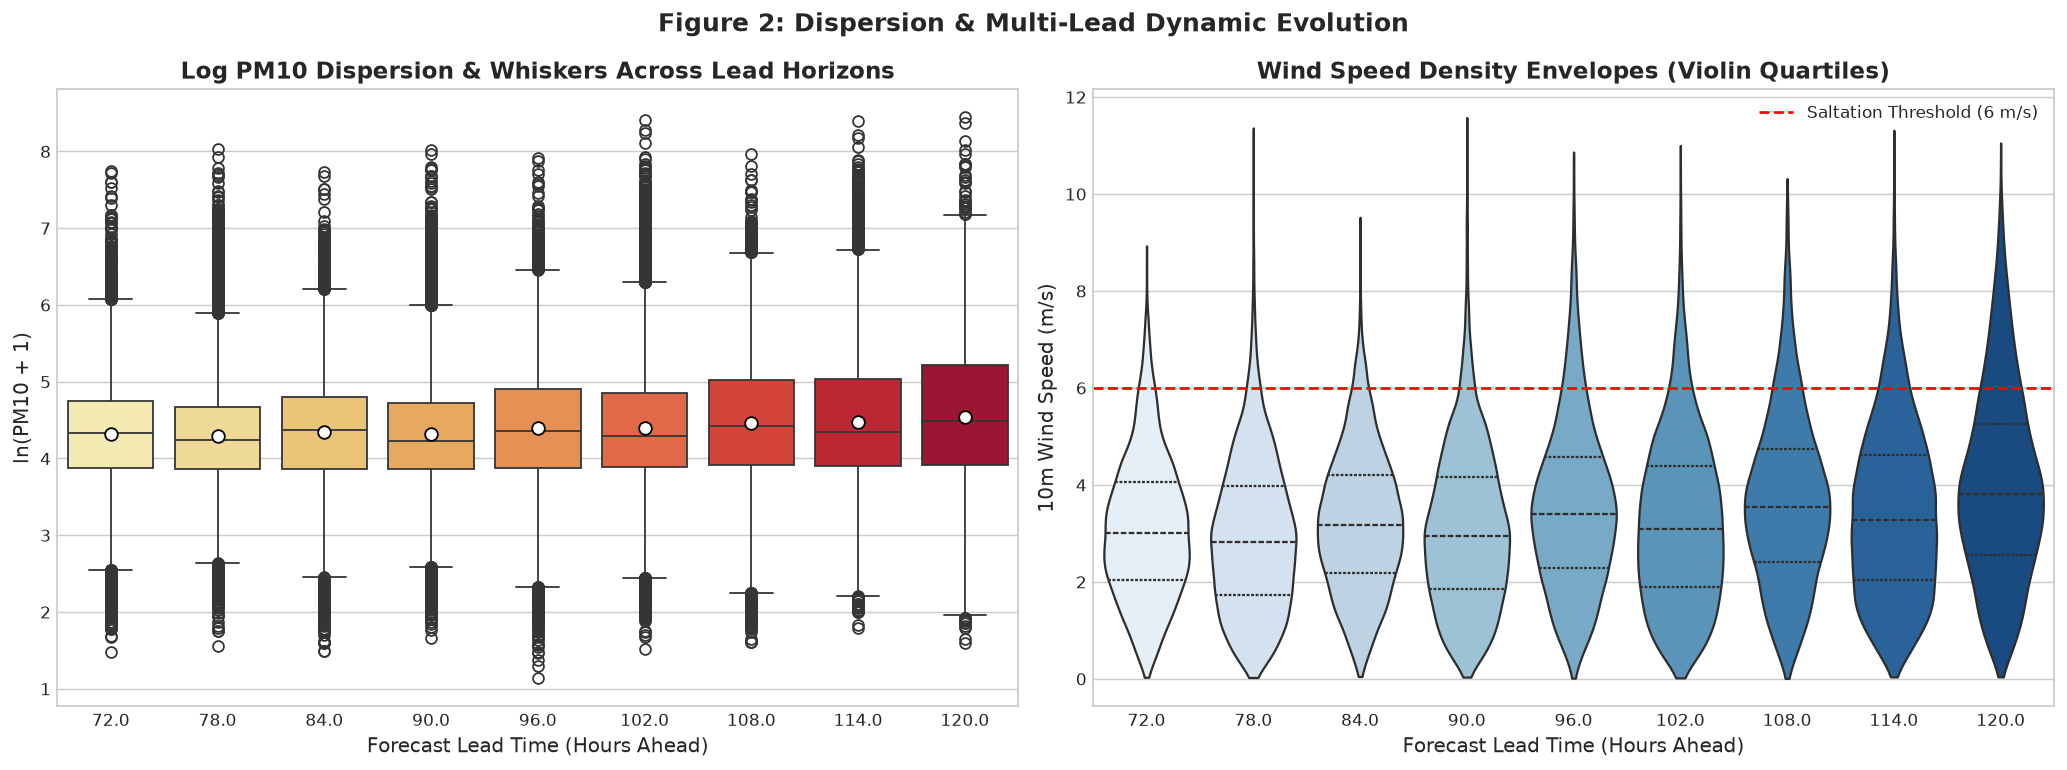

In [4]:
# ==============================================================================
# 2.2 Box Plots & Violin Plots Stratified by Forecast Lead Time (72h to 120h)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Boxplot of log PM10 across lead hours
ax = axes[0]
sns.boxplot(
    data=df, x='lead_hours', y='log_nwp_pm10',
    palette='YlOrRd', ax=ax, showmeans=True,
    meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"7"}
)
ax.set_title("Log PM10 Dispersion & Whiskers Across Lead Horizons", fontweight='bold')
ax.set_xlabel("Forecast Lead Time (Hours Ahead)")
ax.set_ylabel("ln(PM10 + 1)")

# Violin plot of Wind Speed across lead hours
ax = axes[1]
sns.violinplot(
    data=df, x='lead_hours', y='wind_speed_10m',
    palette='Blues', ax=ax, cut=0, inner='quartile'
)
ax.axhline(6.0, color='red', linestyle='--', label='Saltation Threshold (6 m/s)')
ax.set_title("Wind Speed Density Envelopes (Violin Quartiles)", fontweight='bold')
ax.set_xlabel("Forecast Lead Time (Hours Ahead)")
ax.set_ylabel("10m Wind Speed (m/s)")
ax.legend(loc='upper right')

plt.suptitle("Figure 2: Dispersion & Multi-Lead Dynamic Evolution", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


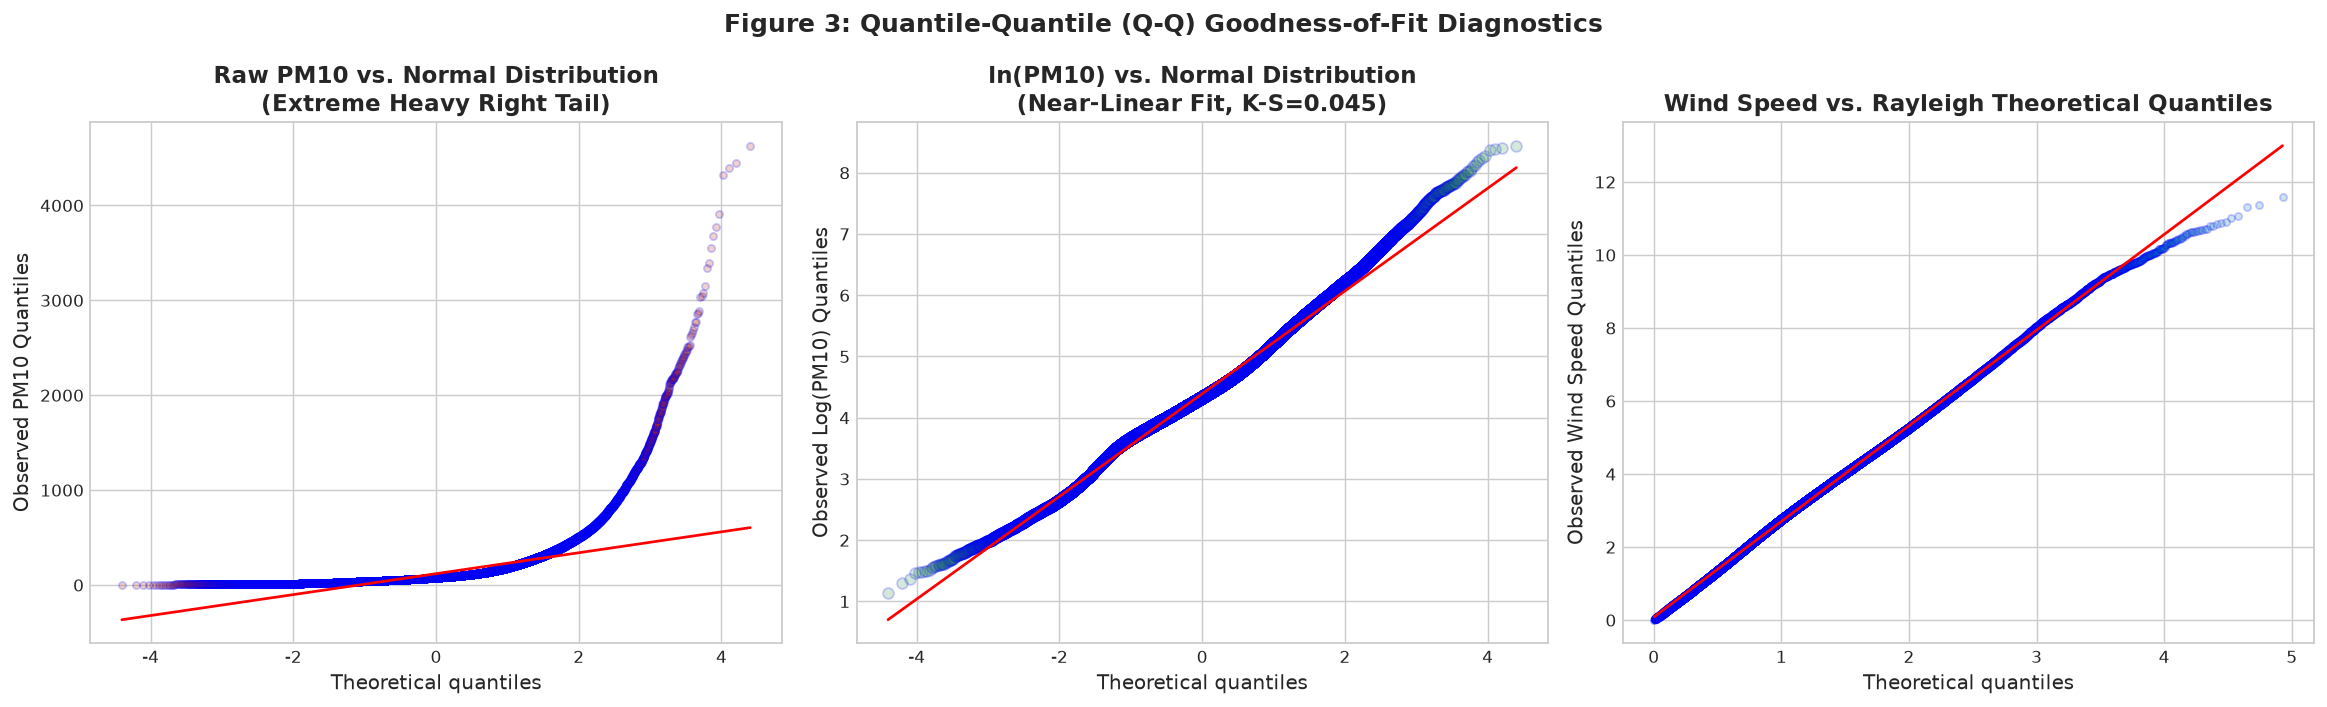

In [5]:
# ==============================================================================
# 2.3 Quantile-Quantile (Q-Q) & Probability Plots for Normality Validation
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. Raw PM10 Q-Q against Gaussian
ax = axes[0]
res1 = stats.probplot(df['nwp_pm10_ugm3'].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor('#AE2012')
ax.get_lines()[0].set_alpha(0.2)
ax.get_lines()[0].set_markersize(4)
ax.set_title("Raw PM10 vs. Normal Distribution\n(Extreme Heavy Right Tail)", fontweight='bold')
ax.set_ylabel("Observed PM10 Quantiles")

# 2. Log(PM10) Q-Q against Gaussian
ax = axes[1]
res2 = stats.probplot(df['log_nwp_pm10'].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor('#2B9348')
ax.get_lines()[0].set_alpha(0.2)
mu_log, std_log = df['log_nwp_pm10'].mean(), df['log_nwp_pm10'].std()
ks_res = stats.kstest(df['log_nwp_pm10'].dropna(), stats.norm(loc=mu_log, scale=std_log).cdf)
ks_stat = ks_res.statistic
ax.set_title(f"ln(PM10) vs. Normal Distribution\n(Near-Linear Fit, K-S={ks_stat:.3f})", fontweight='bold')
ax.set_ylabel("Observed Log(PM10) Quantiles")

# 3. Wind Speed vs. Weibull / Rayleigh
ax = axes[2]
res3 = stats.probplot(df['wind_speed_10m'].dropna(), dist="rayleigh", plot=ax)
ax.get_lines()[0].set_markerfacecolor('#0077B6')
ax.get_lines()[0].set_alpha(0.2)
ax.get_lines()[0].set_markersize(4)
ax.set_title("Wind Speed vs. Rayleigh Theoretical Quantiles", fontweight='bold')
ax.set_ylabel("Observed Wind Speed Quantiles")

plt.suptitle("Figure 3: Quantile-Quantile (Q-Q) Goodness-of-Fit Diagnostics", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


📊 Distribution Moments Table:


,Mean,Std Dev,Median,IQR (Q75-Q25),Skewness,Kurtosis,Min,Max
Variable,,,,,,,,
nwp_pm10_ugm3,118.068001,150.026001,75.166000,81.854,6.523,85.274002,2.107,4628.032227
log_nwp_pm10,4.390000,0.842000,4.333000,0.990,0.244,0.563000,1.134,8.440000
nwp_aod550,0.167000,0.141000,0.134000,0.138,2.197,8.653000,0.000,2.275000
wind_speed_10m,3.362000,1.717000,3.218000,2.348,0.579,0.252000,0.006,11.576000
u_star,0.146000,0.075000,0.140000,0.102,0.579,0.252000,0.000,0.503000
wind_power_flux,70.665001,106.514999,33.331001,77.914,3.547,18.535000,0.000,1551.112061


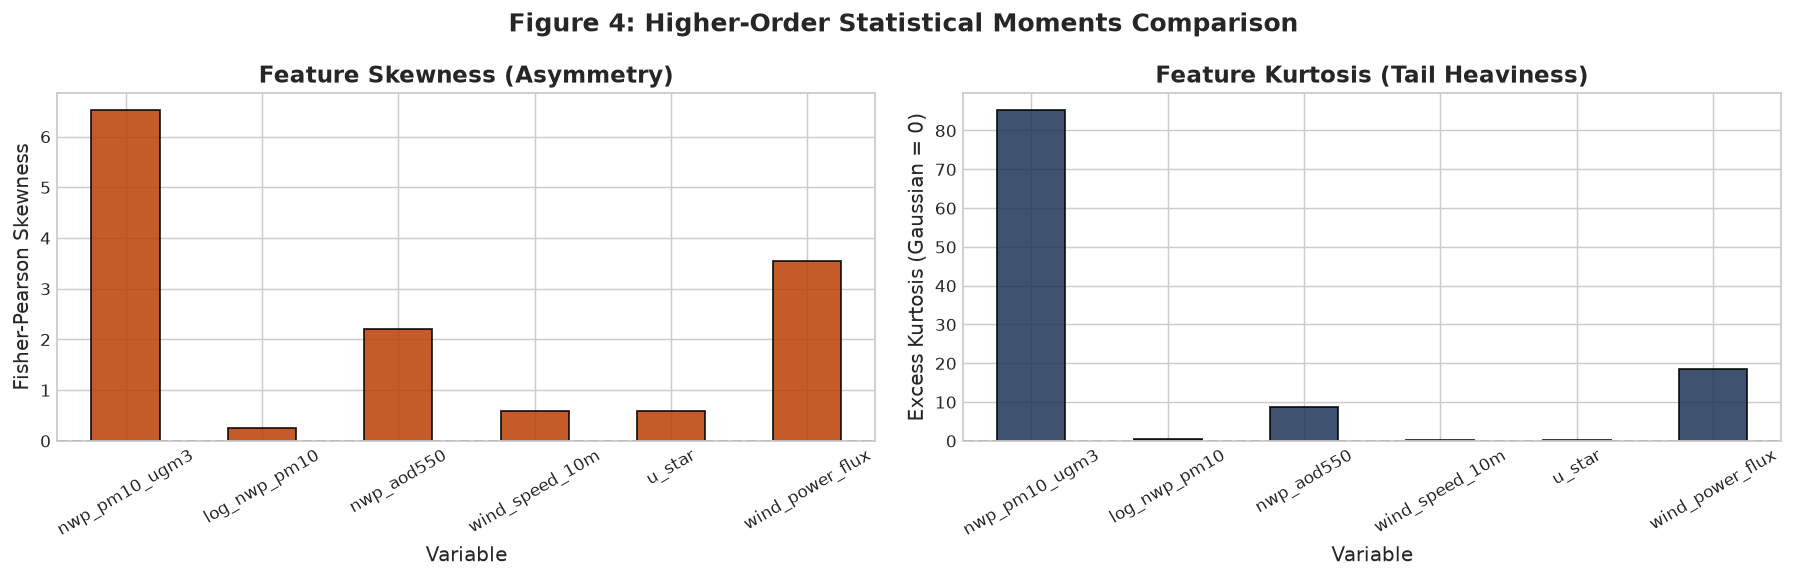

In [6]:
# ==============================================================================
# 2.4 Statistical Moments & Distribution Metrics Summary
# ==============================================================================
metric_vars = ['nwp_pm10_ugm3', 'log_nwp_pm10', 'nwp_aod550', 'wind_speed_10m', 'u_star', 'wind_power_flux']
moment_rows = []

for v in metric_vars:
    vals = df[v].dropna()
    moment_rows.append({
        'Variable': v,
        'Mean': vals.mean(),
        'Std Dev': vals.std(),
        'Median': vals.median(),
        'IQR (Q75-Q25)': vals.quantile(0.75) - vals.quantile(0.25),
        'Skewness': stats.skew(vals),
        'Kurtosis': stats.kurtosis(vals),
        'Min': vals.min(),
        'Max': vals.max()
    })

moments_df = pd.DataFrame(moment_rows).set_index('Variable')
print("📊 Distribution Moments Table:")
display(moments_df.round(3))

# Bar chart of Skewness and Kurtosis
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
moments_df['Skewness'].plot(kind='bar', ax=axes[0], color='#BB3E03', edgecolor='black', alpha=0.85)
axes[0].set_title("Feature Skewness (Asymmetry)", fontweight='bold')
axes[0].set_ylabel("Fisher-Pearson Skewness")
axes[0].axhline(0, color='black', linestyle='--')
axes[0].tick_params(axis='x', rotation=30)

moments_df['Kurtosis'].plot(kind='bar', ax=axes[1], color='#1D3557', edgecolor='black', alpha=0.85)
axes[1].set_title("Feature Kurtosis (Tail Heaviness)", fontweight='bold')
axes[1].set_ylabel("Excess Kurtosis (Gaussian = 0)")
axes[1].axhline(0, color='black', linestyle='--')
axes[1].tick_params(axis='x', rotation=30)

plt.suptitle("Figure 4: Higher-Order Statistical Moments Comparison", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


---
## 3.0 Module 2: Cumulative Distributions & Atmospheric Accumulations ("accumlicaticea")
Cumulative statistics are paramount in atmospheric hazards:
1. **Empirical Cumulative Distribution Function (ECDF):** Quantifies exact percentile exceedance probabilities $P(X \le x)$.
2. **Lorenz Curve & Gini Inequality Coefficient:** Demonstrates that a tiny percentage of severe dust storm events generates the vast majority of atmospheric mass concentration.
3. **Spatial Time-Integrated Cumulative Exposure:** Integrating PM10 concentration across the 5-day forecast horizon ($\int_{72h}^{120h} \text{PM}_{10}(t) dt$) to identify chronic hazard hotspots.
4. **Cumulative Saltation & Kinetic Energy Flux:** Quantifying the cumulative detachment potential across forecast lead times.
5. **Threshold Exceedance Probability Curves:** Forecasting the likelihood of exceeding critical safety thresholds ($>150, >500, >1000\,\mu\text{g}/\text{m}^3$).


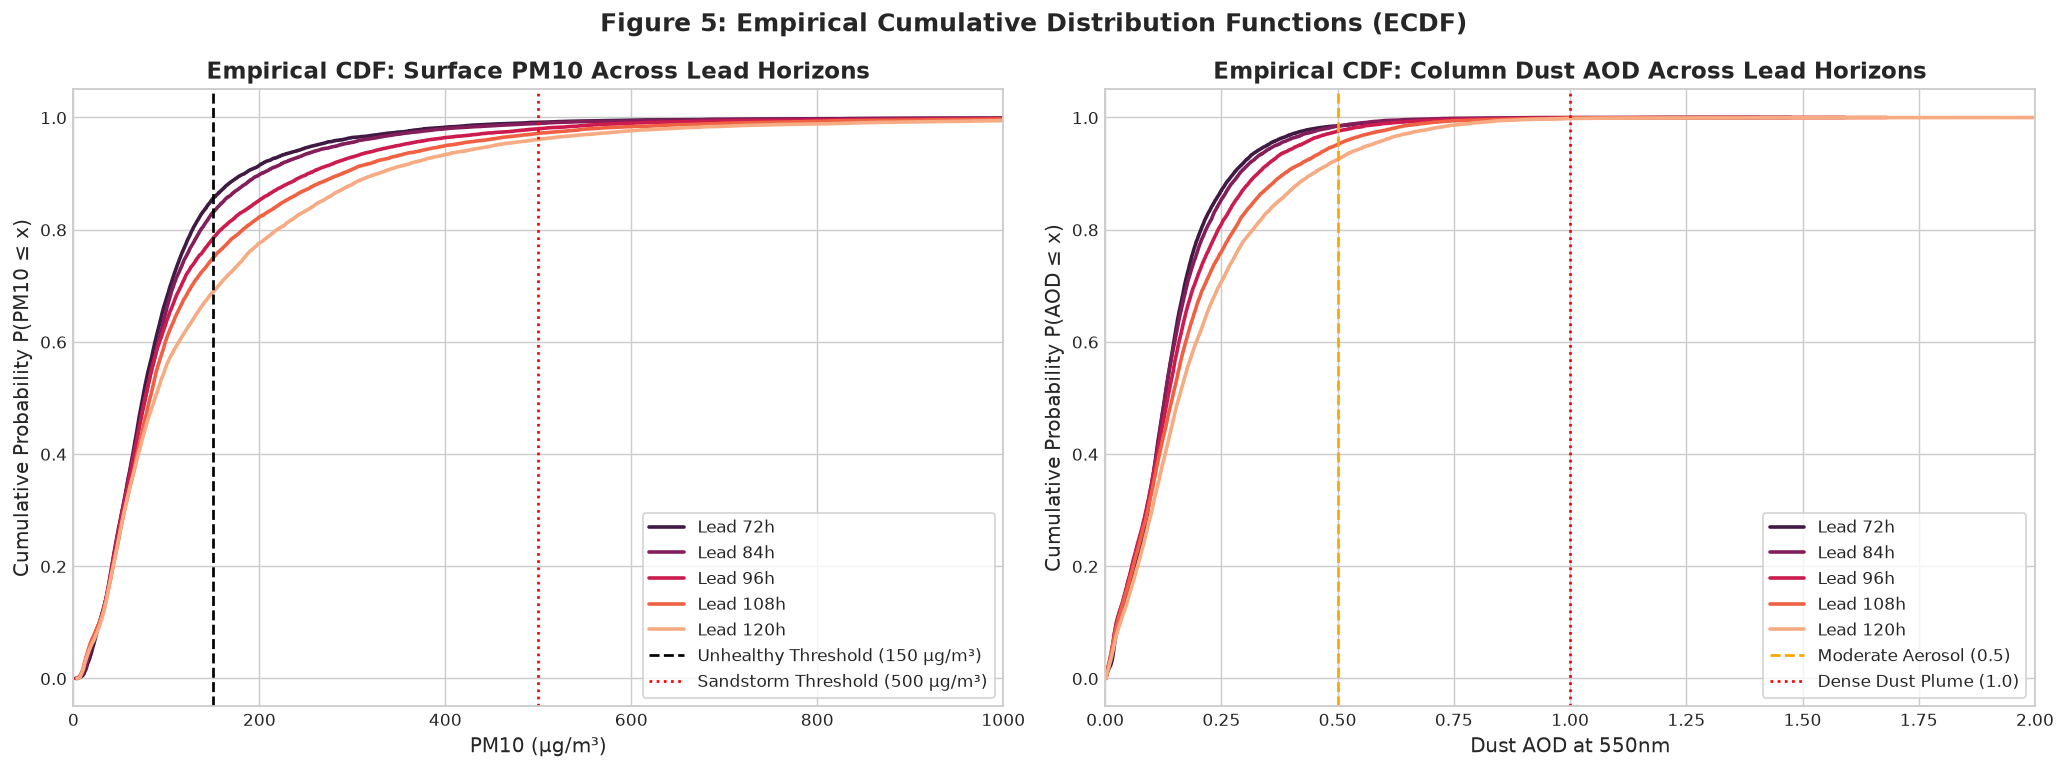

In [7]:
# ==============================================================================
# 3.1 Empirical Cumulative Distribution Functions (ECDF) Across Forecast Leads
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. ECDF for PM10 by Lead Time
ax = axes[0]
leads_to_plot = [72, 84, 96, 108, 120]
colors_lead = sns.color_palette("rocket", len(leads_to_plot))

for lead, col in zip(leads_to_plot, colors_lead):
    sub = df[df['lead_hours'] == lead]['nwp_pm10_ugm3'].dropna().sort_values()
    ecdf_y = np.arange(1, len(sub) + 1) / len(sub)
    ax.plot(sub, ecdf_y, label=f'Lead {lead}h', color=col, linewidth=2)

ax.axvline(150, color='black', linestyle='--', label='Unhealthy Threshold (150 μg/m³)')
ax.axvline(500, color='red', linestyle=':', label='Sandstorm Threshold (500 μg/m³)')
ax.set_title("Empirical CDF: Surface PM10 Across Lead Horizons", fontweight='bold')
ax.set_xlabel("PM10 (μg/m³)")
ax.set_ylabel("Cumulative Probability P(PM10 ≤ x)")
ax.set_xlim(0, 1000)
ax.legend(loc='lower right', frameon=True)

# 2. ECDF for Dust AOD
ax = axes[1]
for lead, col in zip(leads_to_plot, colors_lead):
    sub = df[df['lead_hours'] == lead]['nwp_aod550'].dropna().sort_values()
    ecdf_y = np.arange(1, len(sub) + 1) / len(sub)
    ax.plot(sub, ecdf_y, label=f'Lead {lead}h', color=col, linewidth=2)

ax.axvline(0.5, color='orange', linestyle='--', label='Moderate Aerosol (0.5)')
ax.axvline(1.0, color='red', linestyle=':', label='Dense Dust Plume (1.0)')
ax.set_title("Empirical CDF: Column Dust AOD Across Lead Horizons", fontweight='bold')
ax.set_xlabel("Dust AOD at 550nm")
ax.set_ylabel("Cumulative Probability P(AOD ≤ x)")
ax.set_xlim(0, 2.0)
ax.legend(loc='lower right', frameon=True)

plt.suptitle("Figure 5: Empirical Cumulative Distribution Functions (ECDF)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


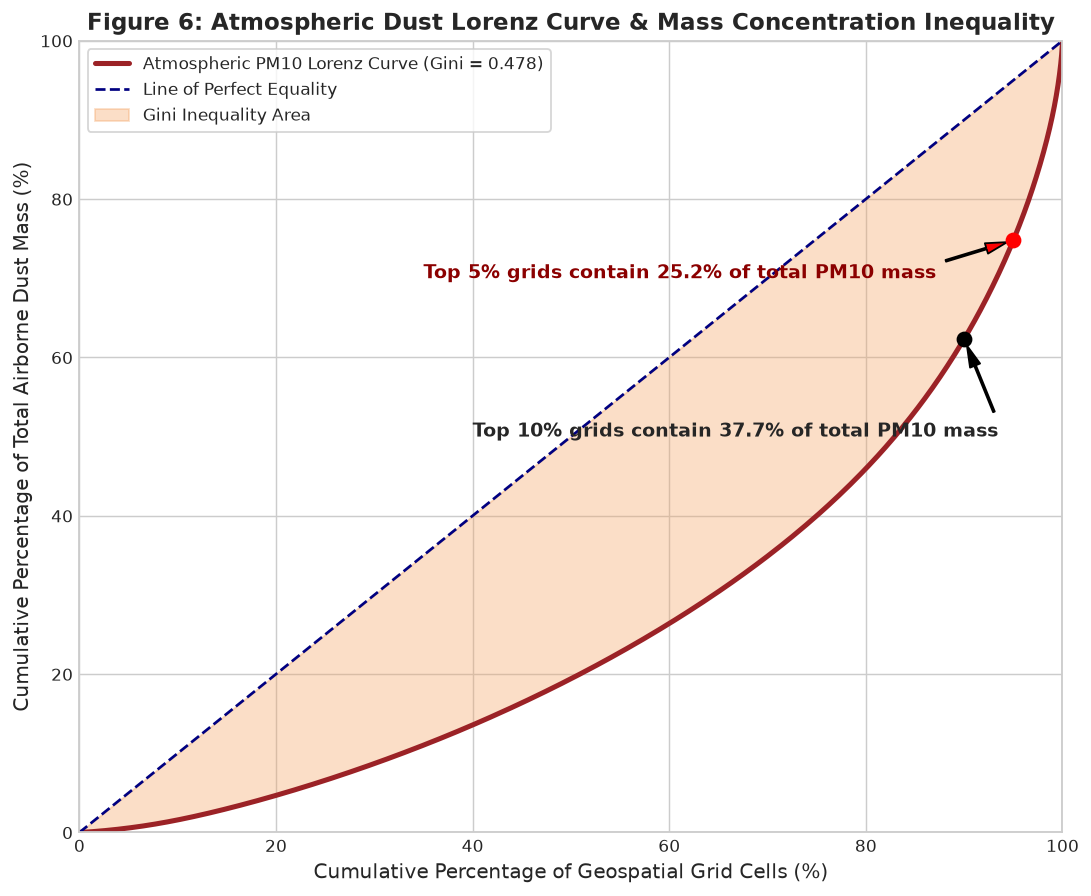

In [8]:
# ==============================================================================
# 3.2 Atmospheric Lorenz Curve & Gini Mass Inequality Coefficient
# ==============================================================================
# Sort values to construct Lorenz curve
sorted_pm10 = np.sort(df['nwp_pm10_ugm3'].values)
n = len(sorted_pm10)
cum_pop = np.arange(1, n + 1) / n
cum_mass = np.cumsum(sorted_pm10) / np.sum(sorted_pm10)

# Calculate Gini Coefficient: G = 1 - 2 * integral of Lorenz curve
trapz_fn = getattr(np, 'trapezoid', getattr(np, 'trapz', None))
gini_coef = 1.0 - 2.0 * trapz_fn(cum_mass, cum_pop)

fig, ax = plt.subplots(figsize=(8.5, 7))
ax.plot(cum_pop * 100, cum_mass * 100, color='#9B2226', linewidth=2.8, label=f'Atmospheric PM10 Lorenz Curve (Gini = {gini_coef:.3f})')
ax.plot([0, 100], [0, 100], color='navy', linestyle='--', linewidth=1.5, label='Line of Perfect Equality')

# Annotate Pareto / Extreme Event Fraction
# Find percentage of mass held by top 10%
top10_mass = (1.0 - np.interp(0.90, cum_pop, cum_mass)) * 100
top5_mass = (1.0 - np.interp(0.95, cum_pop, cum_mass)) * 100
ax.scatter([90], [100 - top10_mass], color='black', s=60, zorder=5)
ax.annotate(f"Top 10% grids contain {top10_mass:.1f}% of total PM10 mass", 
            xy=(90, 100 - top10_mass), xytext=(40, 50),
            arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6),
            fontweight='bold', fontsize=10.5)

ax.scatter([95], [100 - top5_mass], color='red', s=60, zorder=5)
ax.annotate(f"Top 5% grids contain {top5_mass:.1f}% of total PM10 mass", 
            xy=(95, 100 - top5_mass), xytext=(35, 70),
            arrowprops=dict(facecolor='red', shrink=0.08, width=1, headwidth=6),
            fontweight='bold', fontsize=10.5, color='darkred')

ax.fill_between(cum_pop * 100, cum_mass * 100, cum_pop * 100, color='#F4A261', alpha=0.35, label='Gini Inequality Area')
ax.set_title("Figure 6: Atmospheric Dust Lorenz Curve & Mass Concentration Inequality", fontweight='bold', fontsize=13)
ax.set_xlabel("Cumulative Percentage of Geospatial Grid Cells (%)")
ax.set_ylabel("Cumulative Percentage of Total Airborne Dust Mass (%)")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


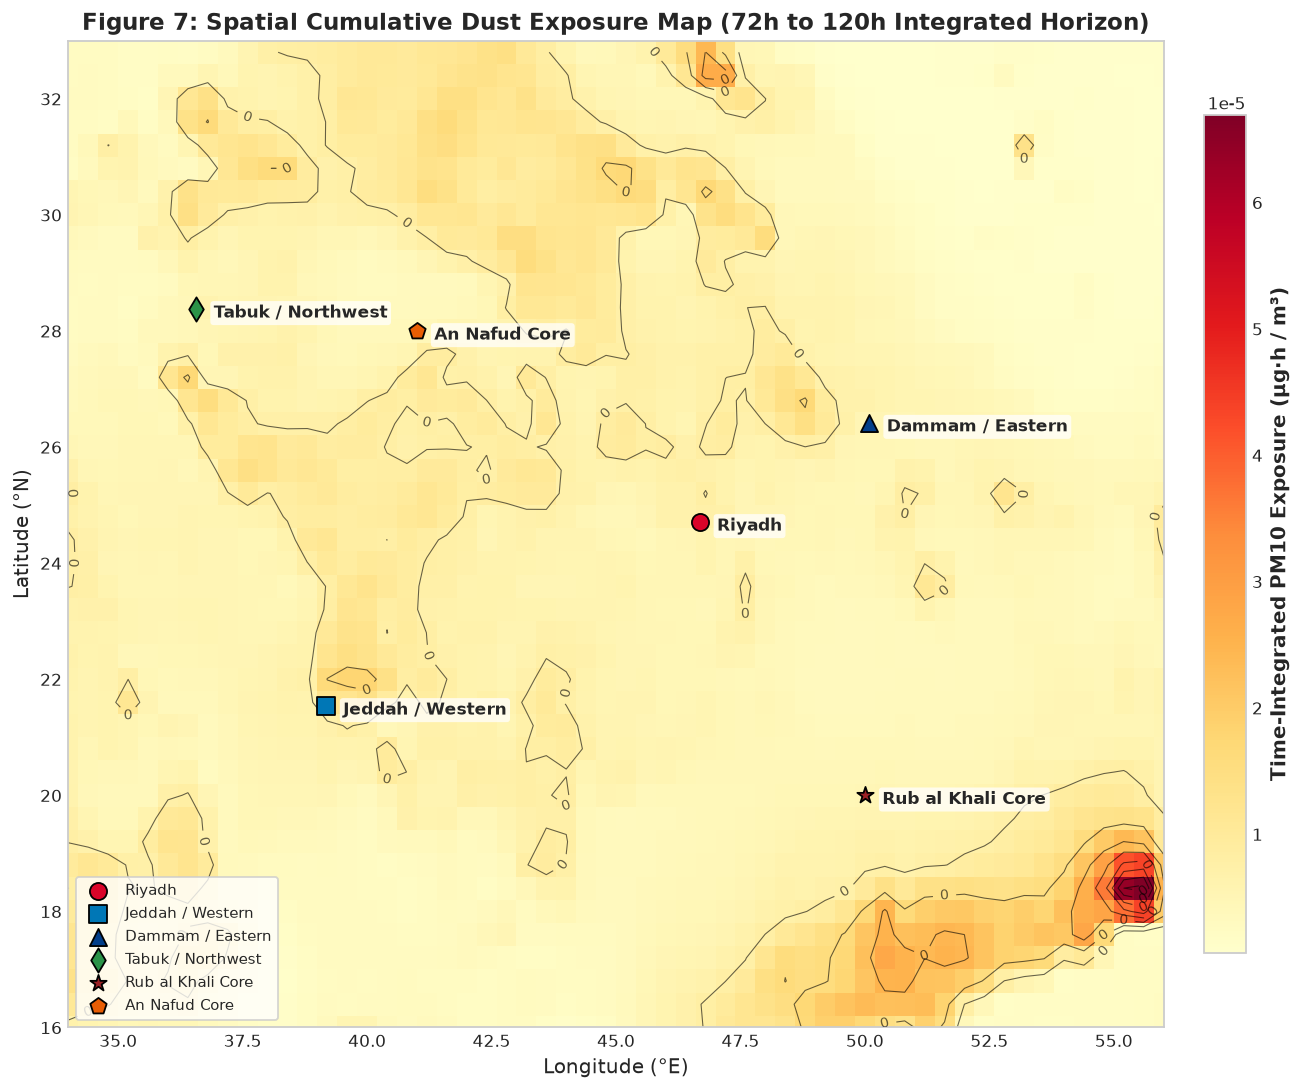

In [9]:
# ==============================================================================
# 3.3 Spatial Time-Integrated Cumulative Exposure (∫ PM10 dt) Over Saudi Arabia
# ==============================================================================
# Using xarray spatial coordinates: compute time-integrated cumulative dust dose across leads
# Lead step is 6 hours (6h = 21,600 seconds)
# Cumulative Dose = sum(pm10_step * 6h)
dt_hours = 6.0

# Mean across forecast reference cycles to get canonical spatial accumulation
pm10_cycle_mean = ds['pm10'].mean(dim='forecast_reference_time')  # (lead, lat, lon)
cumulative_pm10_spatial = pm10_cycle_mean.sum(dim='forecast_period') * dt_hours  # (lat, lon) in μg·h/m³

fig, ax = plt.subplots(figsize=(11, 8.5))
lons = ds['longitude'].values
lats = ds['latitude'].values
mesh = ax.pcolormesh(lons, lats, cumulative_pm10_spatial, cmap='YlOrRd', shading='auto')
cbar = plt.colorbar(mesh, ax=ax, orientation='vertical', pad=0.03, shrink=0.85)
cbar.set_label("Time-Integrated PM10 Exposure (μg·h / m³)", fontweight='bold')

# Contour lines
cs = ax.contour(lons, lats, cumulative_pm10_spatial, levels=8, colors='black', linewidths=0.6, alpha=0.6)
ax.clabel(cs, inline=True, fontsize=8, fmt='%.0f')

# Overlay reference cities
for name, info in CITIES.items():
    ax.scatter(info['lon'], info['lat'], color=info['color'], marker=info['marker'], s=90, edgecolor='black', zorder=6, label=name)
    ax.text(info['lon'] + 0.35, info['lat'] - 0.15, name, fontsize=9.5, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.75, edgecolor='none'))

ax.set_title("Figure 7: Spatial Cumulative Dust Exposure Map (72h to 120h Integrated Horizon)", fontweight='bold', fontsize=13)
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.set_xlim(34, 56)
ax.set_ylim(16, 33)
ax.legend(loc='lower left', frameon=True, fontsize=8.5)
plt.tight_layout()
plt.show()


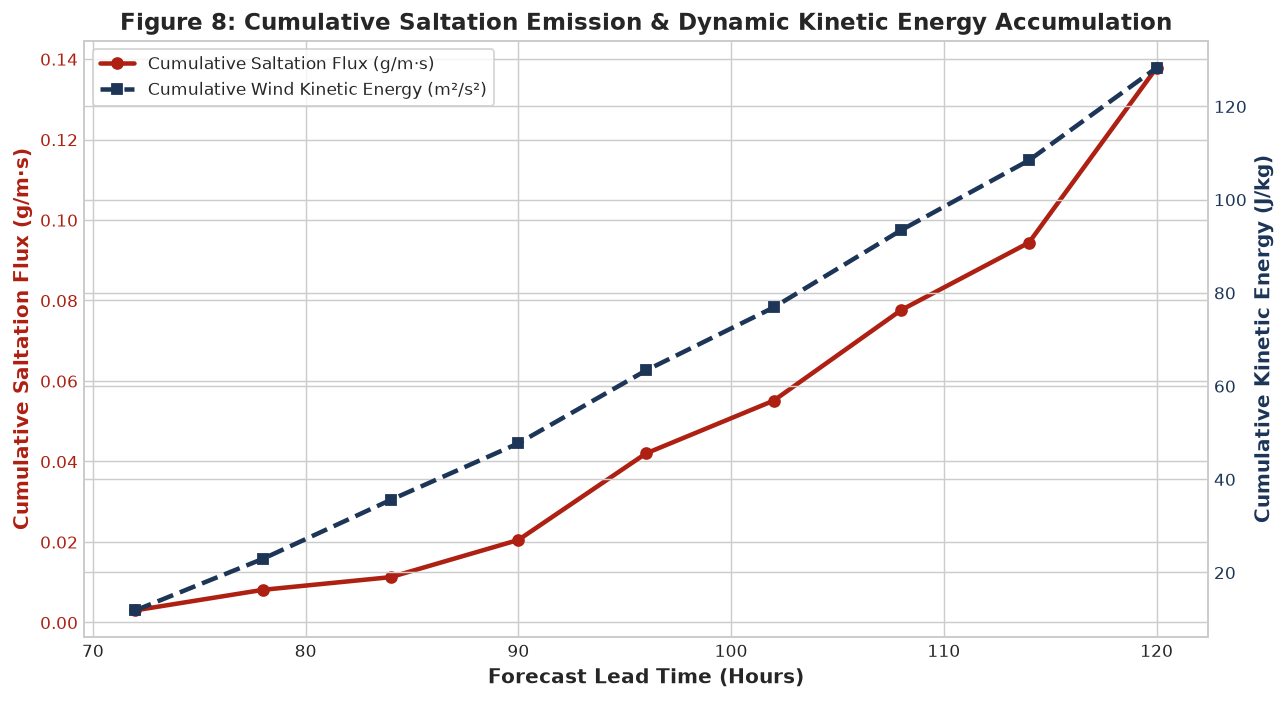

In [10]:
# ==============================================================================
# 3.4 Cumulative Owen Saltation Flux & Kinetic Energy Progression Curve
# ==============================================================================
# Group by lead time to compute cumulative saltation detachment mass
lead_grouped = df.groupby('lead_hours')[['owen_saltation_flux', 'wind_kinetic_energy', 'wind_power_flux']].mean().reset_index()
lead_grouped['cum_saltation_flux'] = lead_grouped['owen_saltation_flux'].cumsum()
lead_grouped['cum_wind_energy'] = lead_grouped['wind_kinetic_energy'].cumsum()

fig, ax1 = plt.subplots(figsize=(10, 5.5))
ax2 = ax1.twinx()

line1 = ax1.plot(lead_grouped['lead_hours'], lead_grouped['cum_saltation_flux'], 
                 color='#AE2012', marker='o', linewidth=2.5, label='Cumulative Saltation Flux (g/m·s)')
line2 = ax2.plot(lead_grouped['lead_hours'], lead_grouped['cum_wind_energy'], 
                 color='#1D3557', marker='s', linestyle='--', linewidth=2.5, label='Cumulative Wind Kinetic Energy (m²/s²)')

ax1.set_xlabel("Forecast Lead Time (Hours)", fontweight='bold')
ax1.set_ylabel("Cumulative Saltation Flux (g/m·s)", color='#AE2012', fontweight='bold')
ax2.set_ylabel("Cumulative Kinetic Energy (J/kg)", color='#1D3557', fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#AE2012')
ax2.tick_params(axis='y', labelcolor='#1D3557')

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', frameon=True)
ax1.set_title("Figure 8: Cumulative Saltation Emission & Dynamic Kinetic Energy Accumulation", fontweight='bold')
plt.tight_layout()
plt.show()


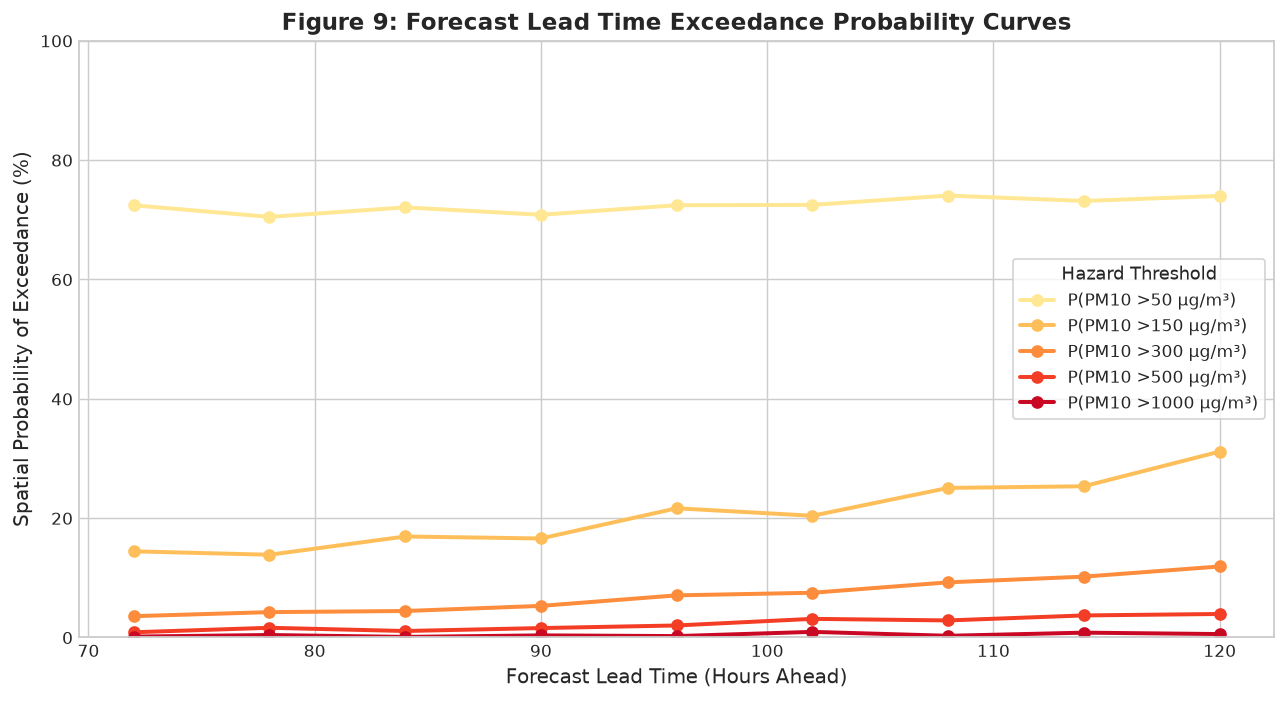

In [11]:
# ==============================================================================
# 3.5 Hazard Exceedance Probability Curves Across Lead Times
# ==============================================================================
thresholds = [50, 150, 300, 500, 1000]
exceed_matrix = []

for lead in sorted(df['lead_hours'].unique()):
    sub_pm10 = df[df['lead_hours'] == lead]['nwp_pm10_ugm3']
    row = {'lead_hours': lead}
    for th in thresholds:
        row[f'>{th} μg/m³'] = (sub_pm10 > th).mean() * 100.0
    exceed_matrix.append(row)

df_exceed = pd.DataFrame(exceed_matrix).set_index('lead_hours')

fig, ax = plt.subplots(figsize=(10, 5.5))
palette_th = sns.color_palette("YlOrRd", len(thresholds))

for (col, c) in zip(df_exceed.columns, palette_th):
    ax.plot(df_exceed.index, df_exceed[col], marker='o', linewidth=2.2, label=f'P(PM10 {col})', color=c)

ax.set_title("Figure 9: Forecast Lead Time Exceedance Probability Curves", fontweight='bold', fontsize=13)
ax.set_xlabel("Forecast Lead Time (Hours Ahead)")
ax.set_ylabel("Spatial Probability of Exceedance (%)")
ax.set_ylim(0, 100)
ax.legend(title="Hazard Threshold", frameon=True)
plt.tight_layout()
plt.show()


---
## 4.0 Module 3: Bivariate & Joint Distributions (Data Science Relationships)
When analyzing massive meteorological data ($>100,000$ points), standard scatter plots suffer from fatal overplotting. We utilize:
1. **Hexagonal 2D Binning (`hexbin`) with Marginal Histograms** to reveal true high-density bivariate probability cores.
2. **Non-Linear Regression Fits (Polynomial & LOWESS Splines)** examining wind saltation thresholds ($W_{10}$ vs $\text{PM}_{10}$).
3. **Bivariate KDE Contours & Friction Velocity Excess:** Friction velocity $u_* - u_{*t}$ vs saltation emission flux.
4. **Surface-to-Column Optical Ratio Dynamics:** Comparing column AOD against surface concentration.


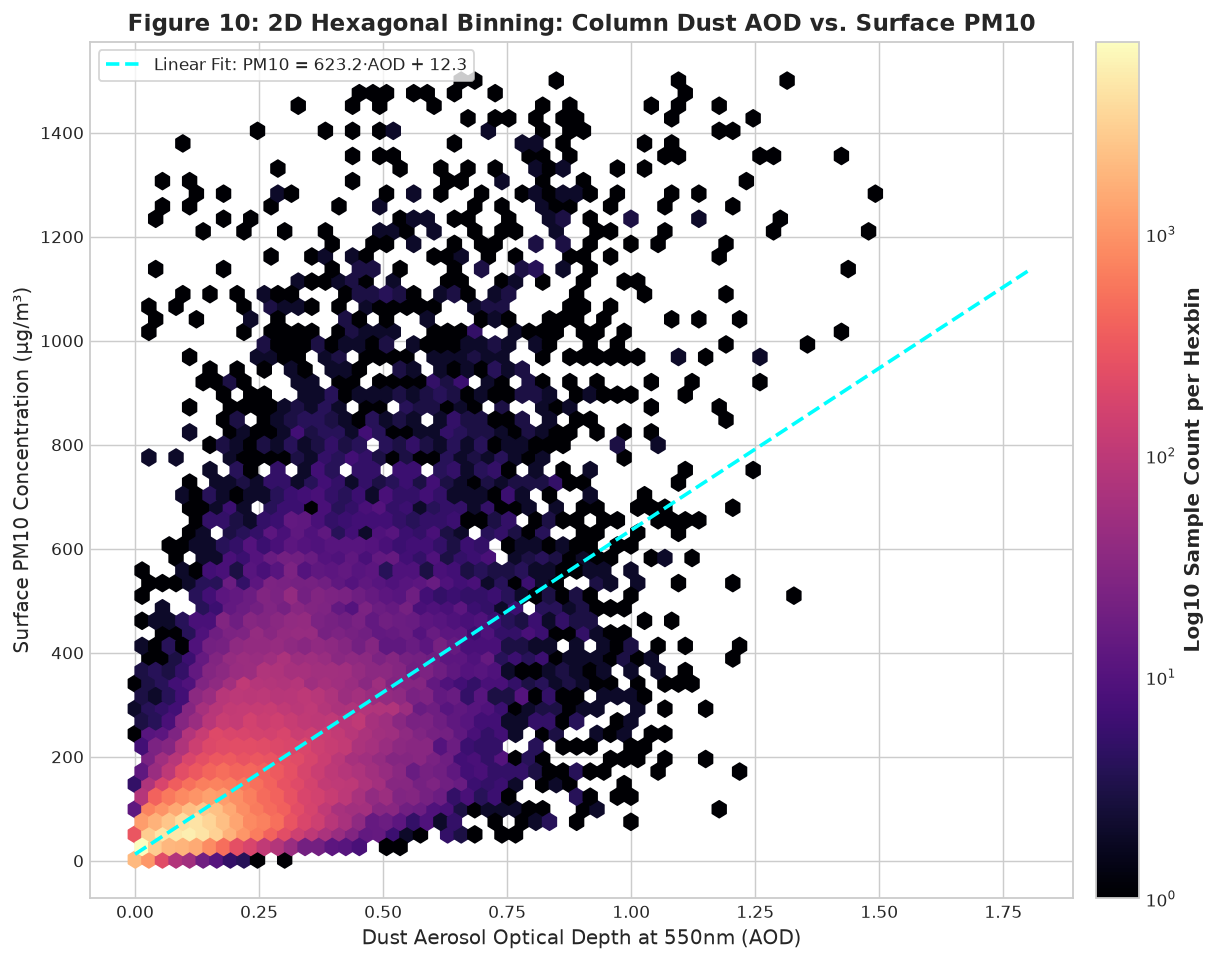

In [12]:
# ==============================================================================
# 4.1 Hexbin 2D Density Distribution: Dust AOD vs Surface PM10
# ==============================================================================
fig, ax = plt.subplots(figsize=(10, 7.5))

# Filter extreme outliers for focused visualization
mask = (df['nwp_aod550'] < 1.8) & (df['nwp_pm10_ugm3'] < 1500)
hb = ax.hexbin(
    df.loc[mask, 'nwp_aod550'],
    df.loc[mask, 'nwp_pm10_ugm3'],
    gridsize=55, cmap='magma', bins='log', mincnt=1
)
cb = plt.colorbar(hb, ax=ax, pad=0.02)
cb.set_label("Log10 Sample Count per Hexbin", fontweight='bold')

# Add linear trend line
m, b = np.polyfit(df.loc[mask, 'nwp_aod550'], df.loc[mask, 'nwp_pm10_ugm3'], 1)
x_vals = np.linspace(0, 1.8, 100)
ax.plot(x_vals, m * x_vals + b, 'cyan', linestyle='--', linewidth=2, label=f'Linear Fit: PM10 = {m:.1f}·AOD + {b:.1f}')

ax.set_title("Figure 10: 2D Hexagonal Binning: Column Dust AOD vs. Surface PM10", fontweight='bold', fontsize=13)
ax.set_xlabel("Dust Aerosol Optical Depth at 550nm (AOD)")
ax.set_ylabel("Surface PM10 Concentration (μg/m³)")
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


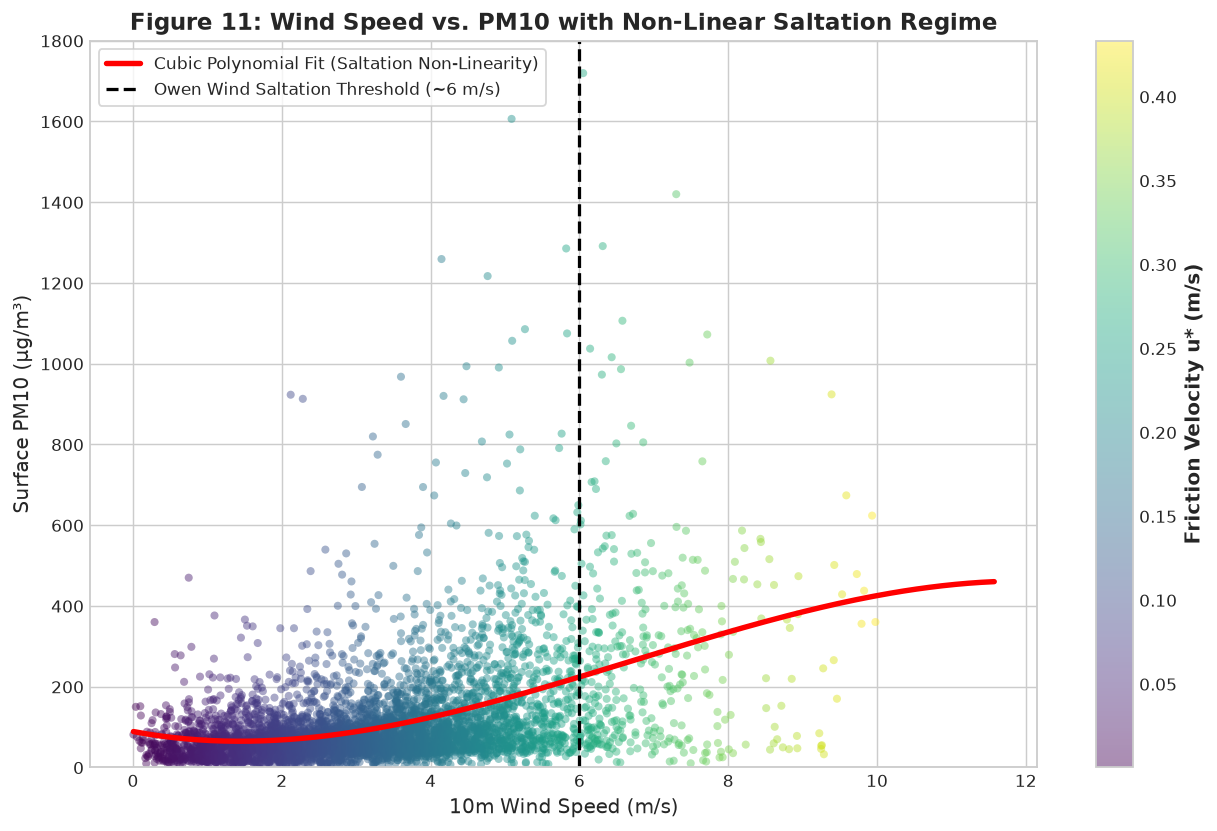

In [13]:
# ==============================================================================
# 4.2 Non-Linear Regression & Saltation Threshold: Wind Speed vs PM10
# ==============================================================================
fig, ax = plt.subplots(figsize=(10, 6.5))

# Subsample for clear scatter demonstration
sample_df = df.sample(n=5000, random_state=42)
sc = ax.scatter(sample_df['wind_speed_10m'], sample_df['nwp_pm10_ugm3'], 
                c=sample_df['u_star'], cmap='viridis', alpha=0.45, s=20, edgecolors='none')
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Friction Velocity u* (m/s)", fontweight='bold')

# Fit 3rd degree polynomial to capture non-linear saltation acceleration
poly_coeffs = np.polyfit(df['wind_speed_10m'], df['nwp_pm10_ugm3'], deg=3)
poly_func = np.poly1d(poly_coeffs)
w_space = np.linspace(df['wind_speed_10m'].min(), df['wind_speed_10m'].max(), 200)

ax.plot(w_space, poly_func(w_space), color='red', linewidth=3, label=f'Cubic Polynomial Fit (Saltation Non-Linearity)')
ax.axvline(6.0, color='black', linestyle='--', linewidth=1.8, label='Owen Wind Saltation Threshold (~6 m/s)')

ax.set_title("Figure 11: Wind Speed vs. PM10 with Non-Linear Saltation Regime", fontweight='bold', fontsize=13)
ax.set_xlabel("10m Wind Speed (m/s)")
ax.set_ylabel("Surface PM10 (μg/m³)")
ax.set_ylim(0, 1800)
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


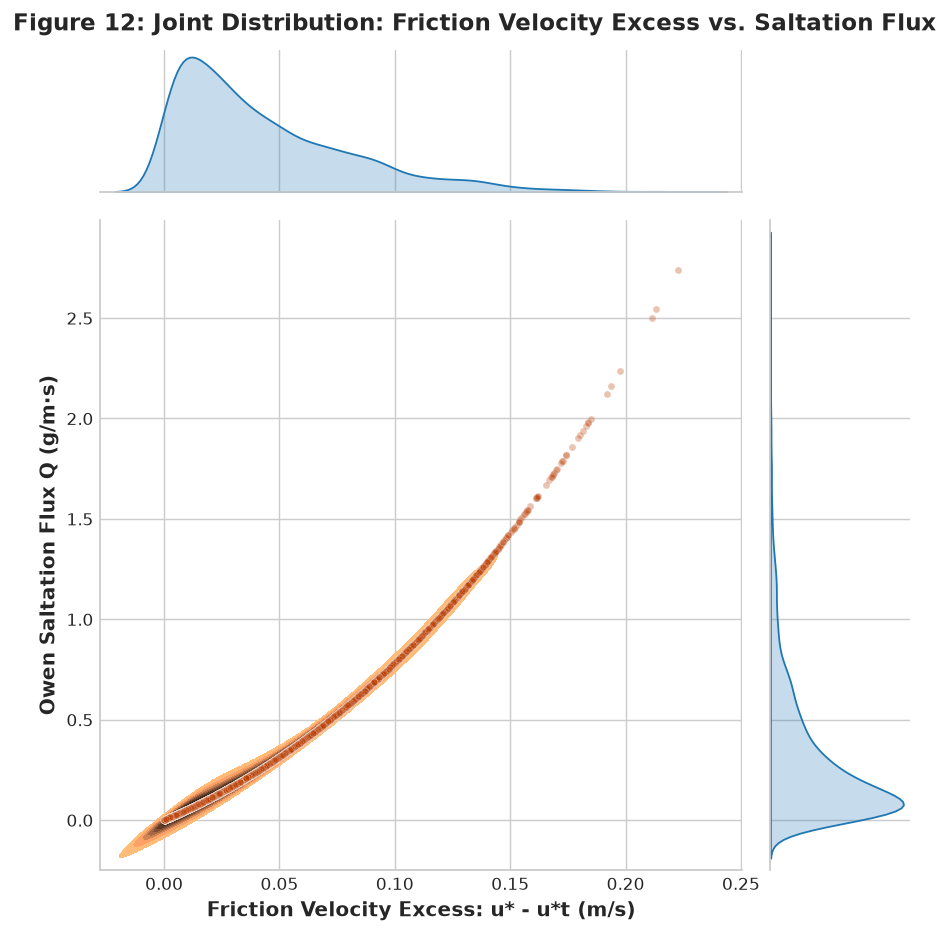

In [14]:
# ==============================================================================
# 4.3 Joint Marginal Distribution: Friction Velocity Excess vs. Saltation Flux
# ==============================================================================
# Take positive excess cases
salt_df = df[df['u_star_excess'] > 0].sample(n=4000, random_state=42)

g = sns.jointplot(
    data=salt_df,
    x='u_star_excess',
    y='owen_saltation_flux',
    kind='kde',
    cmap='copper_r',
    fill=True,
    height=7,
    ratio=4,
    thresh=0.05
)
g.plot_joint(sns.scatterplot, s=15, alpha=0.3, color='#BB3E03')
g.fig.suptitle("Figure 12: Joint Distribution: Friction Velocity Excess vs. Saltation Flux", y=1.02, fontweight='bold', fontsize=13)
g.ax_joint.set_xlabel("Friction Velocity Excess: u* - u*t (m/s)", fontweight='bold')
g.ax_joint.set_ylabel("Owen Saltation Flux Q (g/m·s)", fontweight='bold')
plt.show()


---
## 5.0 Module 4: Multivariate Analytics & Dimensionality Reduction
In multi-predictor atmospheric modeling, evaluating multicollinearity and capturing low-dimensional manifolds is essential.
1. **Triangular Correlation Heatmaps:** Pearson linear correlation and Spearman monotonic rank correlation.
2. **Principal Component Analysis (PCA):** Scree variance decomposition, 2D/3D state projections, and feature loading vectors.


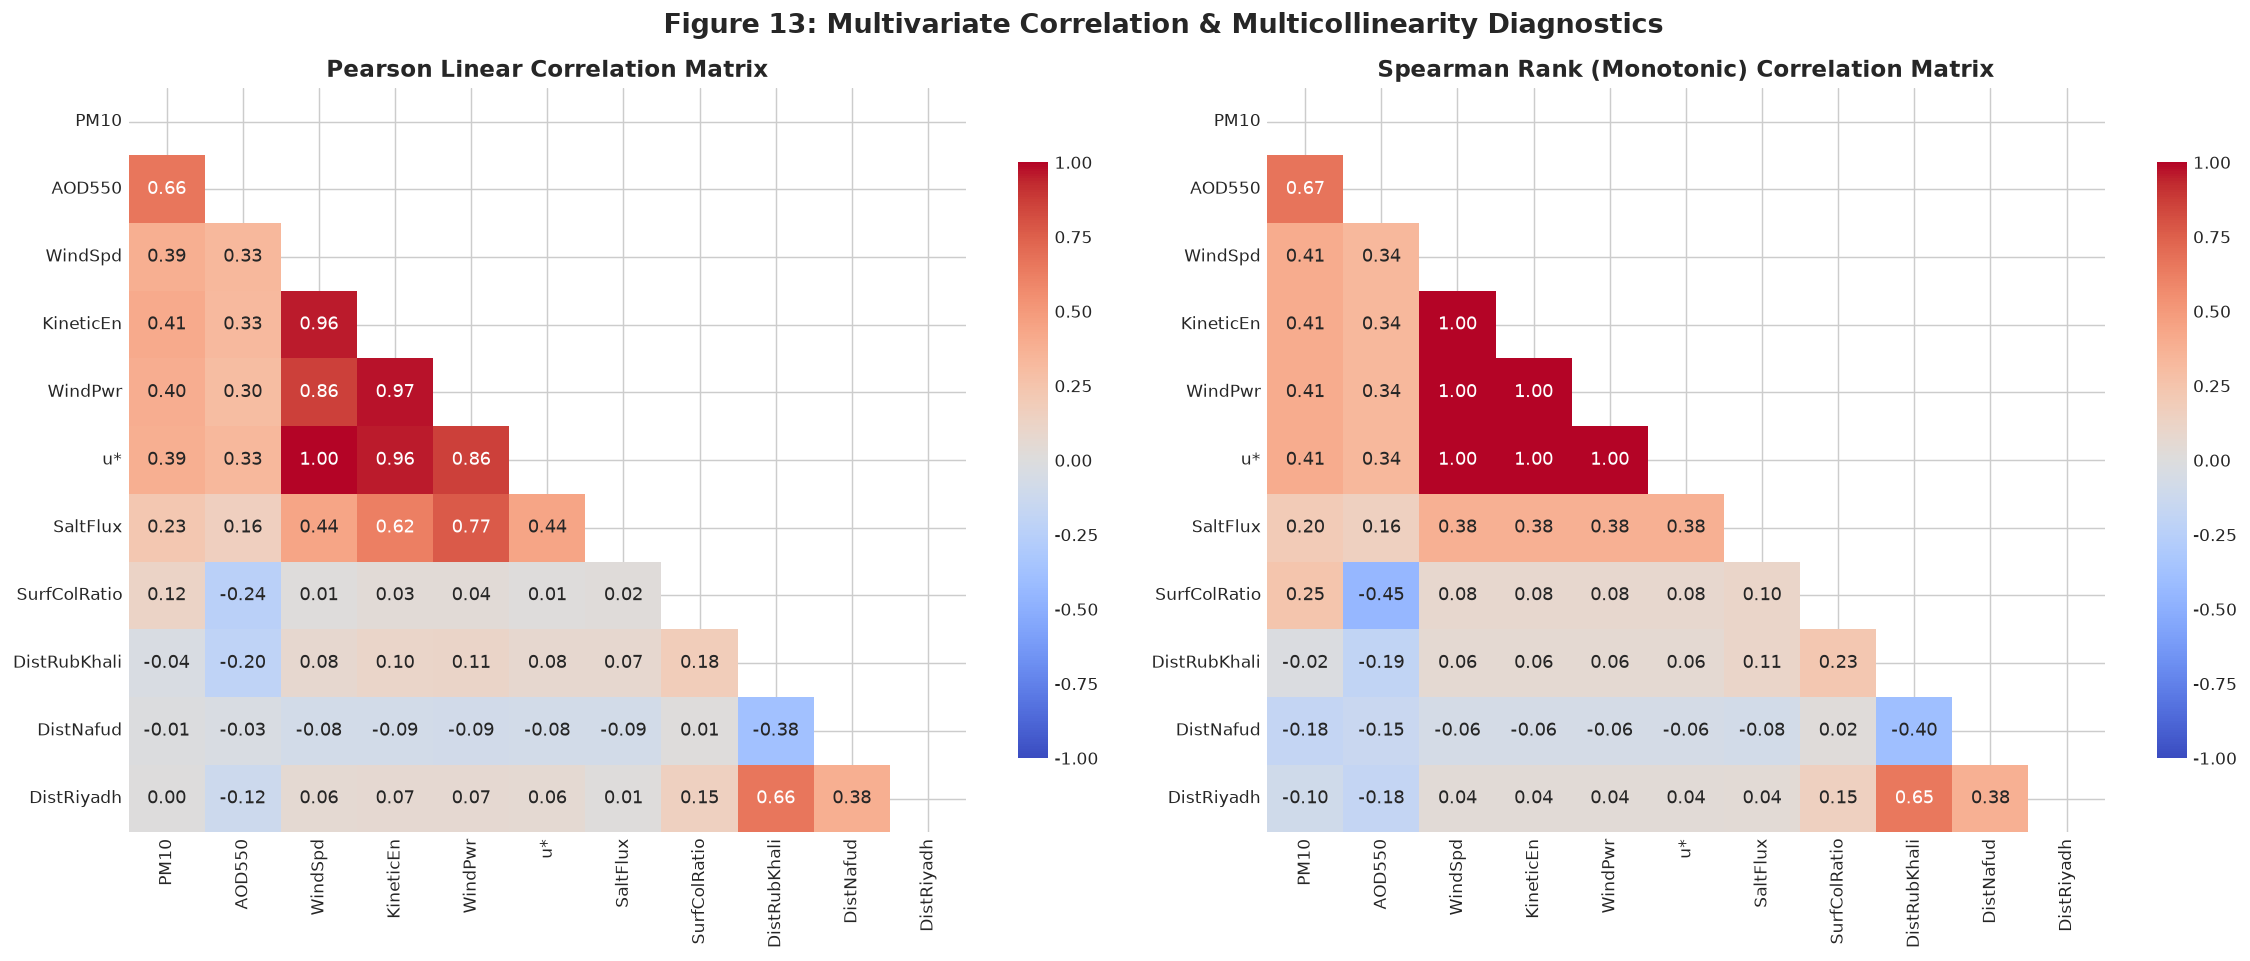

In [15]:
# ==============================================================================
# 5.1 Correlation Heatmaps: Pearson (Linear) vs. Spearman (Monotonic)
# ==============================================================================
corr_cols = [
    'nwp_pm10_ugm3', 'nwp_aod550', 'wind_speed_10m', 'wind_kinetic_energy',
    'wind_power_flux', 'u_star', 'owen_saltation_flux', 'surface_to_column_ratio',
    'dist_rub_al_khali_km', 'dist_an_nafud_km', 'dist_riyadh_km'
]
short_labels = [
    'PM10', 'AOD550', 'WindSpd', 'KineticEn',
    'WindPwr', 'u*', 'SaltFlux', 'SurfColRatio',
    'DistRubKhali', 'DistNafud', 'DistRiyadh'
]

df_corr = df[corr_cols].dropna()
pearson_corr = df_corr.corr(method='pearson')
spearman_corr = df_corr.corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))

# Mask upper triangle
mask_tri = np.triu(np.ones_like(pearson_corr, dtype=bool))

# Pearson
sns.heatmap(
    pearson_corr, mask=mask_tri, cmap='coolwarm', vmin=-1, vmax=1,
    annot=True, fmt='.2f', xticklabels=short_labels, yticklabels=short_labels,
    ax=axes[0], cbar_kws={'shrink': 0.8}
)
axes[0].set_title("Pearson Linear Correlation Matrix", fontweight='bold', fontsize=13)

# Spearman
sns.heatmap(
    spearman_corr, mask=mask_tri, cmap='coolwarm', vmin=-1, vmax=1,
    annot=True, fmt='.2f', xticklabels=short_labels, yticklabels=short_labels,
    ax=axes[1], cbar_kws={'shrink': 0.8}
)
axes[1].set_title("Spearman Rank (Monotonic) Correlation Matrix", fontweight='bold', fontsize=13)

plt.suptitle("Figure 13: Multivariate Correlation & Multicollinearity Diagnostics", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


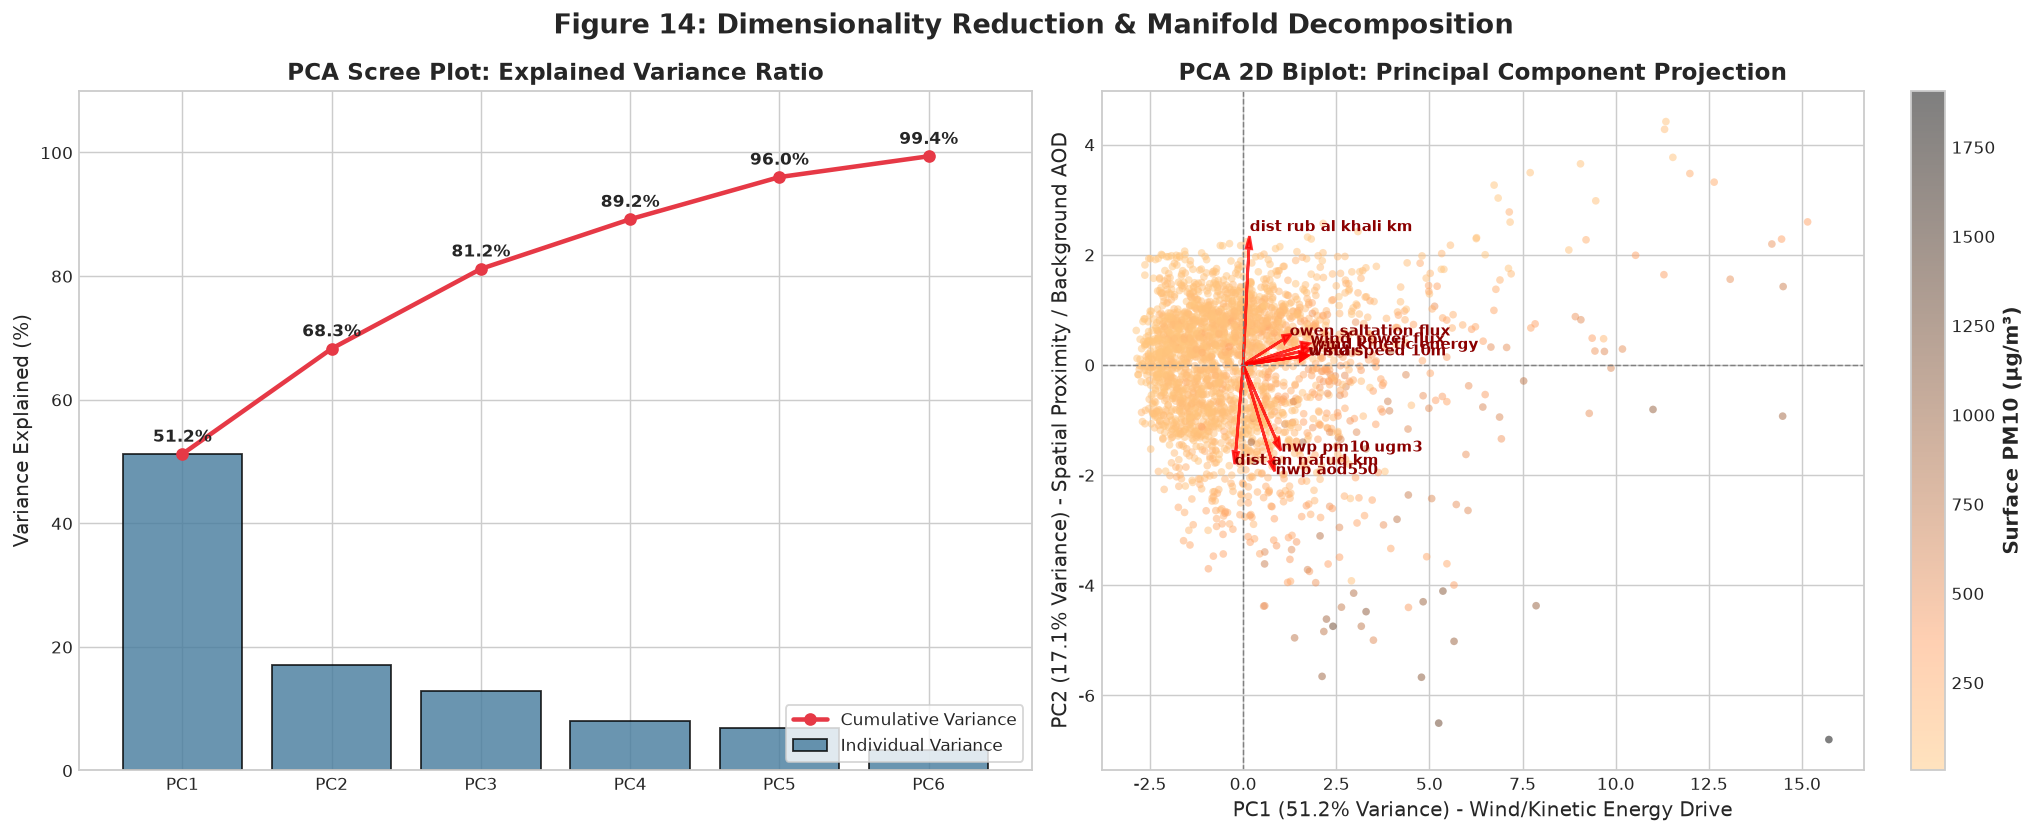

In [16]:
# ==============================================================================
# 5.2 Principal Component Analysis (PCA): Scree Plot & 2D Projection Biplot
# ==============================================================================
# Select numeric features for dimensionality reduction
pca_features = [
    'nwp_pm10_ugm3', 'nwp_aod550', 'wind_speed_10m', 'wind_kinetic_energy',
    'wind_power_flux', 'u_star', 'owen_saltation_flux', 'dist_rub_al_khali_km', 'dist_an_nafud_km'
]
X_pca = df[pca_features].dropna()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_pca)

pca = PCA(n_components=6)
X_trans = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# 1. Scree Plot (Explained Variance)
ax = axes[0]
exp_var = pca.explained_variance_ratio_ * 100
cum_var = np.cumsum(exp_var)
x_bars = [f'PC{i+1}' for i in range(len(exp_var))]

ax.bar(x_bars, exp_var, color='#457B9D', alpha=0.8, edgecolor='black', label='Individual Variance')
ax.plot(x_bars, cum_var, color='#E63946', marker='o', linewidth=2.5, label='Cumulative Variance')
for i, v in enumerate(cum_var):
    ax.text(i, v + 2, f'{v:.1f}%', ha='center', fontweight='bold', fontsize=9.5)

ax.set_title("PCA Scree Plot: Explained Variance Ratio", fontweight='bold')
ax.set_ylabel("Variance Explained (%)")
ax.set_ylim(0, 110)
ax.legend(loc='lower right', frameon=True)

# 2. PCA 2D Biplot (PC1 vs PC2)
ax = axes[1]
# Sample for visual clarity
idx_sample = np.random.RandomState(42).choice(len(X_trans), size=2500, replace=False)
scatter = ax.scatter(
    X_trans[idx_sample, 0], X_trans[idx_sample, 1],
    c=X_pca.iloc[idx_sample]['nwp_pm10_ugm3'], cmap='copper_r',
    alpha=0.5, s=18, edgecolors='none'
)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Surface PM10 (μg/m³)", fontweight='bold')

# Plot feature loading vectors
scale_vec = 3.5
for i, feat in enumerate(pca_features):
    ax.arrow(0, 0, pca.components_[0, i] * scale_vec, pca.components_[1, i] * scale_vec,
             color='red', alpha=0.8, head_width=0.15, linewidth=1.5)
    ax.text(pca.components_[0, i] * scale_vec * 1.15, pca.components_[1, i] * scale_vec * 1.15,
            feat.replace('_', ' '), color='darkred', fontweight='bold', fontsize=8.5)

ax.set_title("PCA 2D Biplot: Principal Component Projection", fontweight='bold')
ax.set_xlabel(f"PC1 ({exp_var[0]:.1f}% Variance) - Wind/Kinetic Energy Drive")
ax.set_ylabel(f"PC2 ({exp_var[1]:.1f}% Variance) - Spatial Proximity / Background AOD")
ax.axhline(0, color='grey', linestyle='--', linewidth=0.8)
ax.axvline(0, color='grey', linestyle='--', linewidth=0.8)

plt.suptitle("Figure 14: Dimensionality Reduction & Manifold Decomposition", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


---
## 6.0 Module 5: Directional Dynamics & Polar Wind-Dust Roses
Wind direction governs sandstorm transport across the Arabian Peninsula. 
- **Shamal Winds:** Powerful north/northwesterly winds channeling massive plumes southward from Iraq/Kuwait and An Nafud into the Rub' al Khali and Riyadh.
- **Polar Wind Rose:** Frequency and intensity of winds by 16 directional bins.
- **Directional Dust Flux Rose:** Dust mass weighted by wind direction.
- **Regional Radar / Spider Profile:** Multivariate multi-axis comparison of desert corridors.


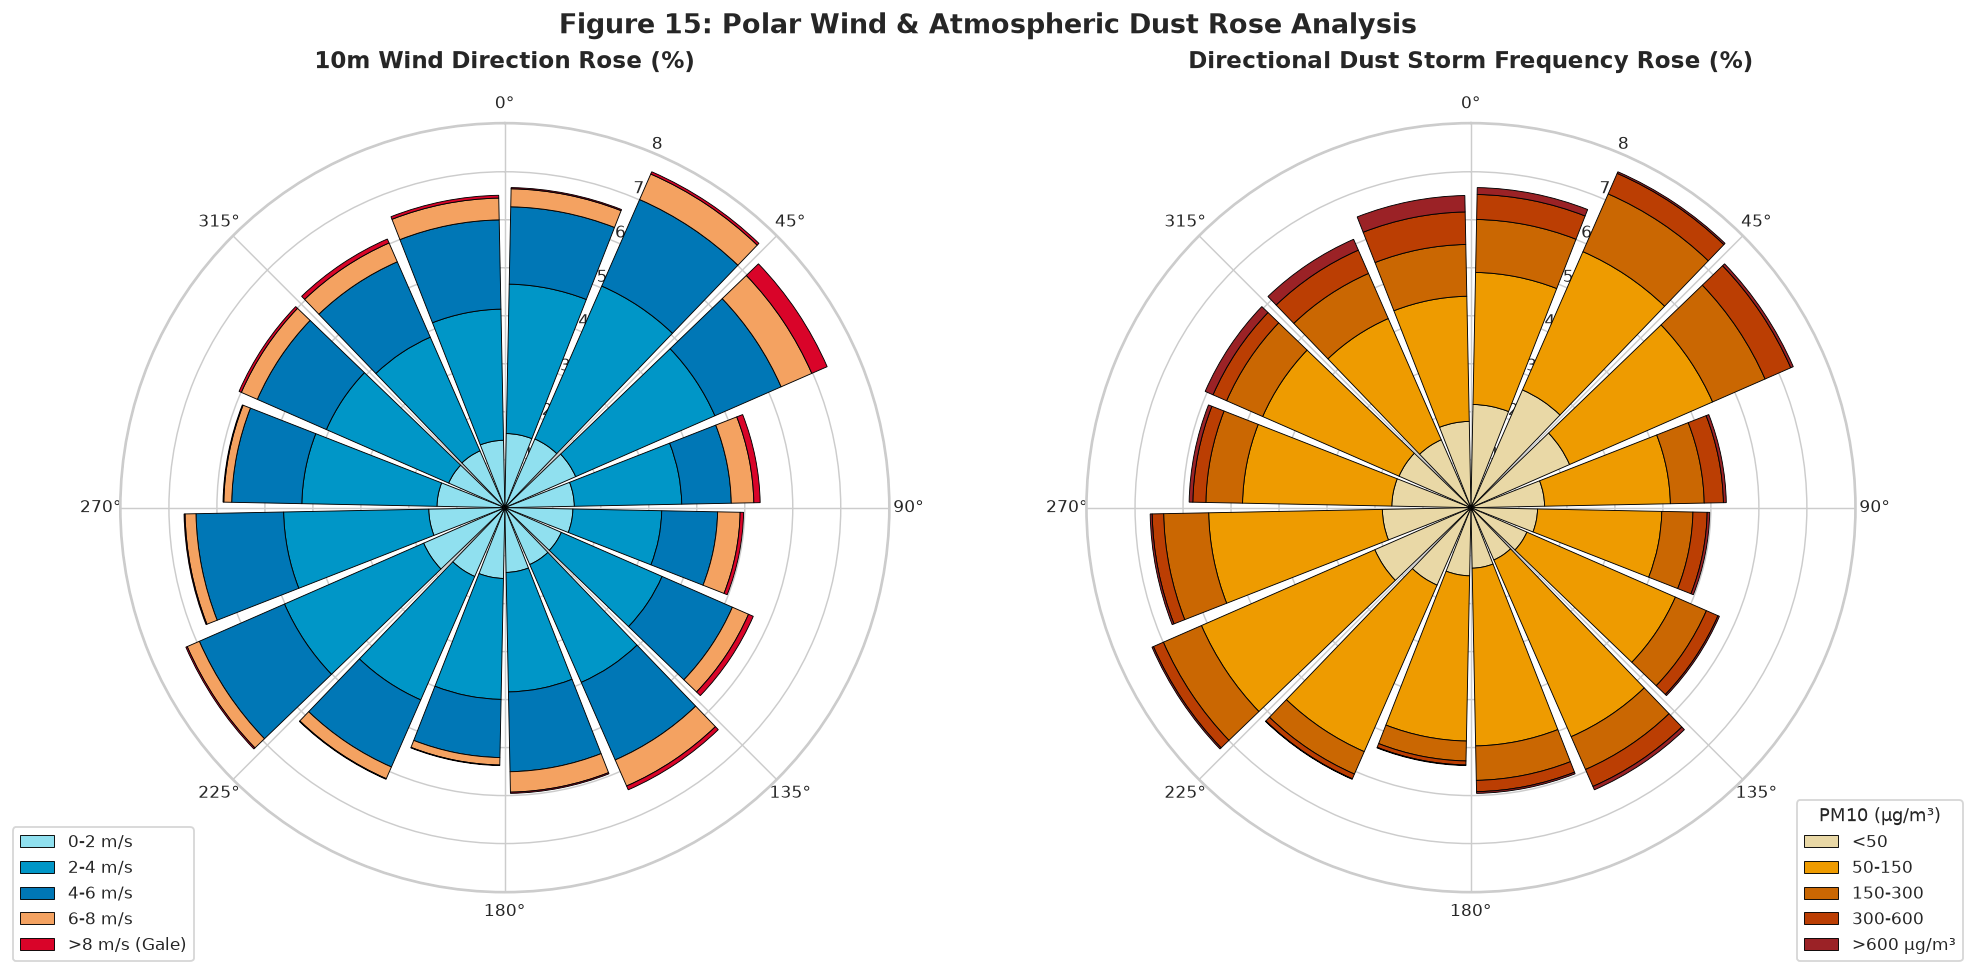

In [17]:
# ==============================================================================
# 6.1 Polar Wind Rose & Directional Dust Flux Rose
# ==============================================================================
# Bin wind direction into 16 sectors (22.5 degrees each)
num_sectors = 16
sector_width = 360 / num_sectors
dir_bins = np.linspace(0, 360, num_sectors + 1)
bin_centers = np.radians(dir_bins[:-1] + sector_width / 2)

df['wind_dir_bin'] = pd.cut(df['wind_direction_deg'], bins=dir_bins, labels=False, include_lowest=True)

# 1. Wind Speed counts by sector
speed_bins = [0, 2, 4, 6, 8, 15]
speed_labels = ['0-2 m/s', '2-4 m/s', '4-6 m/s', '6-8 m/s', '>8 m/s (Gale)']
colors_speed = ['#90E0EF', '#0096C7', '#0077B6', '#F4A261', '#D90429']

fig = plt.figure(figsize=(16, 7.5))

# Subplot 1: Wind Rose
ax1 = fig.add_subplot(1, 2, 1, polar=True)
ax1.set_theta_zero_location('N')
ax1.set_theta_direction(-1)  # Clockwise

bottom = np.zeros(num_sectors)
total_samples = len(df)

for i in range(len(speed_bins) - 1):
    low, high = speed_bins[i], speed_bins[i + 1]
    sub = df[(df['wind_speed_10m'] >= low) & (df['wind_speed_10m'] < high)]
    counts = sub['wind_dir_bin'].value_counts().reindex(range(num_sectors), fill_value=0).values
    pcts = (counts / total_samples) * 100.0
    ax1.bar(bin_centers, pcts, width=np.radians(sector_width * 0.9), bottom=bottom, 
            color=colors_speed[i], edgecolor='black', linewidth=0.5, label=speed_labels[i])
    bottom += pcts

ax1.set_title("10m Wind Direction Rose (%)", fontweight='bold', pad=15)
ax1.legend(loc='lower left', bbox_to_anchor=(-0.15, -0.1), frameon=True)

# Subplot 2: PM10 Weighted Flux Rose
ax2 = fig.add_subplot(1, 2, 2, polar=True)
ax2.set_theta_zero_location('N')
ax2.set_theta_direction(-1)

# PM10 bins
pm10_bins = [0, 50, 150, 300, 600, 3000]
pm10_labels = ['<50', '50-150', '150-300', '300-600', '>600 μg/m³']
colors_pm10 = ['#E9D8A6', '#EE9B00', '#CA6702', '#BB3E03', '#9B2226']

bottom_pm = np.zeros(num_sectors)
for i in range(len(pm10_bins) - 1):
    low, high = pm10_bins[i], pm10_bins[i + 1]
    sub = df[(df['nwp_pm10_ugm3'] >= low) & (df['nwp_pm10_ugm3'] < high)]
    counts = sub['wind_dir_bin'].value_counts().reindex(range(num_sectors), fill_value=0).values
    pcts = (counts / total_samples) * 100.0
    ax2.bar(bin_centers, pcts, width=np.radians(sector_width * 0.9), bottom=bottom_pm,
            color=colors_pm10[i], edgecolor='black', linewidth=0.5, label=pm10_labels[i])
    bottom_pm += pcts

ax2.set_title("Directional Dust Storm Frequency Rose (%)", fontweight='bold', pad=15)
ax2.legend(loc='lower right', bbox_to_anchor=(1.15, -0.1), frameon=True, title='PM10 (μg/m³)')

plt.suptitle("Figure 15: Polar Wind & Atmospheric Dust Rose Analysis", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


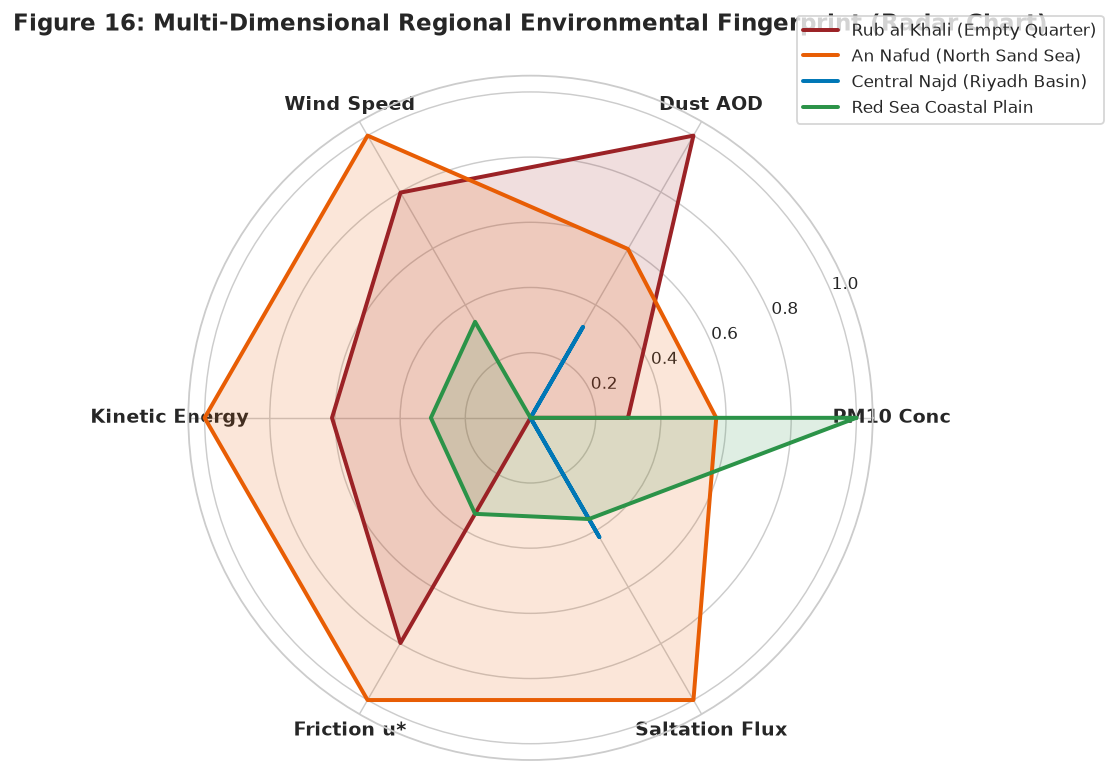

In [18]:
# ==============================================================================
# 6.2 Radar / Spider Chart: Regional Meteorological & Dust Fingerprints
# ==============================================================================
# Define regional bounding boxes
regions = {
    'Rub al Khali (Empty Quarter)': df[(df['latitude'] >= 18) & (df['latitude'] <= 23) & (df['longitude'] >= 47) & (df['longitude'] <= 54)],
    'An Nafud (North Sand Sea)': df[(df['latitude'] >= 27) & (df['latitude'] <= 30) & (df['longitude'] >= 39) & (df['longitude'] <= 44)],
    'Central Najd (Riyadh Basin)': df[(df['latitude'] >= 23) & (df['latitude'] <= 26) & (df['longitude'] >= 45) & (df['longitude'] <= 48)],
    'Red Sea Coastal Plain': df[(df['latitude'] >= 19) & (df['latitude'] <= 24) & (df['longitude'] >= 38) & (df['longitude'] <= 41)]
}

radar_metrics = ['nwp_pm10_ugm3', 'nwp_aod550', 'wind_speed_10m', 'wind_kinetic_energy', 'u_star', 'owen_saltation_flux']
metric_display = ['PM10 Conc', 'Dust AOD', 'Wind Speed', 'Kinetic Energy', 'Friction u*', 'Saltation Flux']

# Normalize across all regions (0 to 1 min-max)
agg_data = pd.DataFrame({reg: sub[radar_metrics].mean() for reg, sub in regions.items()}).T
norm_data = (agg_data - agg_data.min()) / (agg_data.max() - agg_data.min() + 1e-6)

# Set radar angles
num_vars = len(radar_metrics)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]  # Complete loop

fig, ax = plt.subplots(figsize=(8.5, 8.5), subplot_kw=dict(polar=True))
colors_radar = ['#9B2226', '#E85D04', '#0077B6', '#2B9348']

for i, (reg, row) in enumerate(norm_data.iterrows()):
    values = row.tolist()
    values += values[:1]
    ax.plot(angles, values, color=colors_radar[i], linewidth=2.2, label=reg)
    ax.fill(angles, values, color=colors_radar[i], alpha=0.15)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(metric_display, fontweight='bold', fontsize=10.5)
ax.set_ylim(0, 1.05)
ax.set_title("Figure 16: Multi-Dimensional Regional Environmental Fingerprint (Radar Chart)", 
             fontweight='bold', fontsize=13, pad=25)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), frameon=True)
plt.tight_layout()
plt.show()


---
## 7.0 Module 6: Geospatial Synoptic & Atmospheric Flow Visualizations
Geospatial visualization reveals the spatial coherence of the dust storm:
1. **Synoptic Dual-Panel Contours:** Side-by-side surface $\text{PM}_{10}$ and column $\text{AOD}$ across Saudi Arabia.
2. **Velocity Quiver & Atmospheric Streamlines:** $10\text{m}$ wind vector fields superimposed onto dust plumes.
3. **Multi-Lead Spatiotemporal Small Multiples:** Faceted progression from $72\text{h} \to 120\text{h}$ tracking plume displacement.


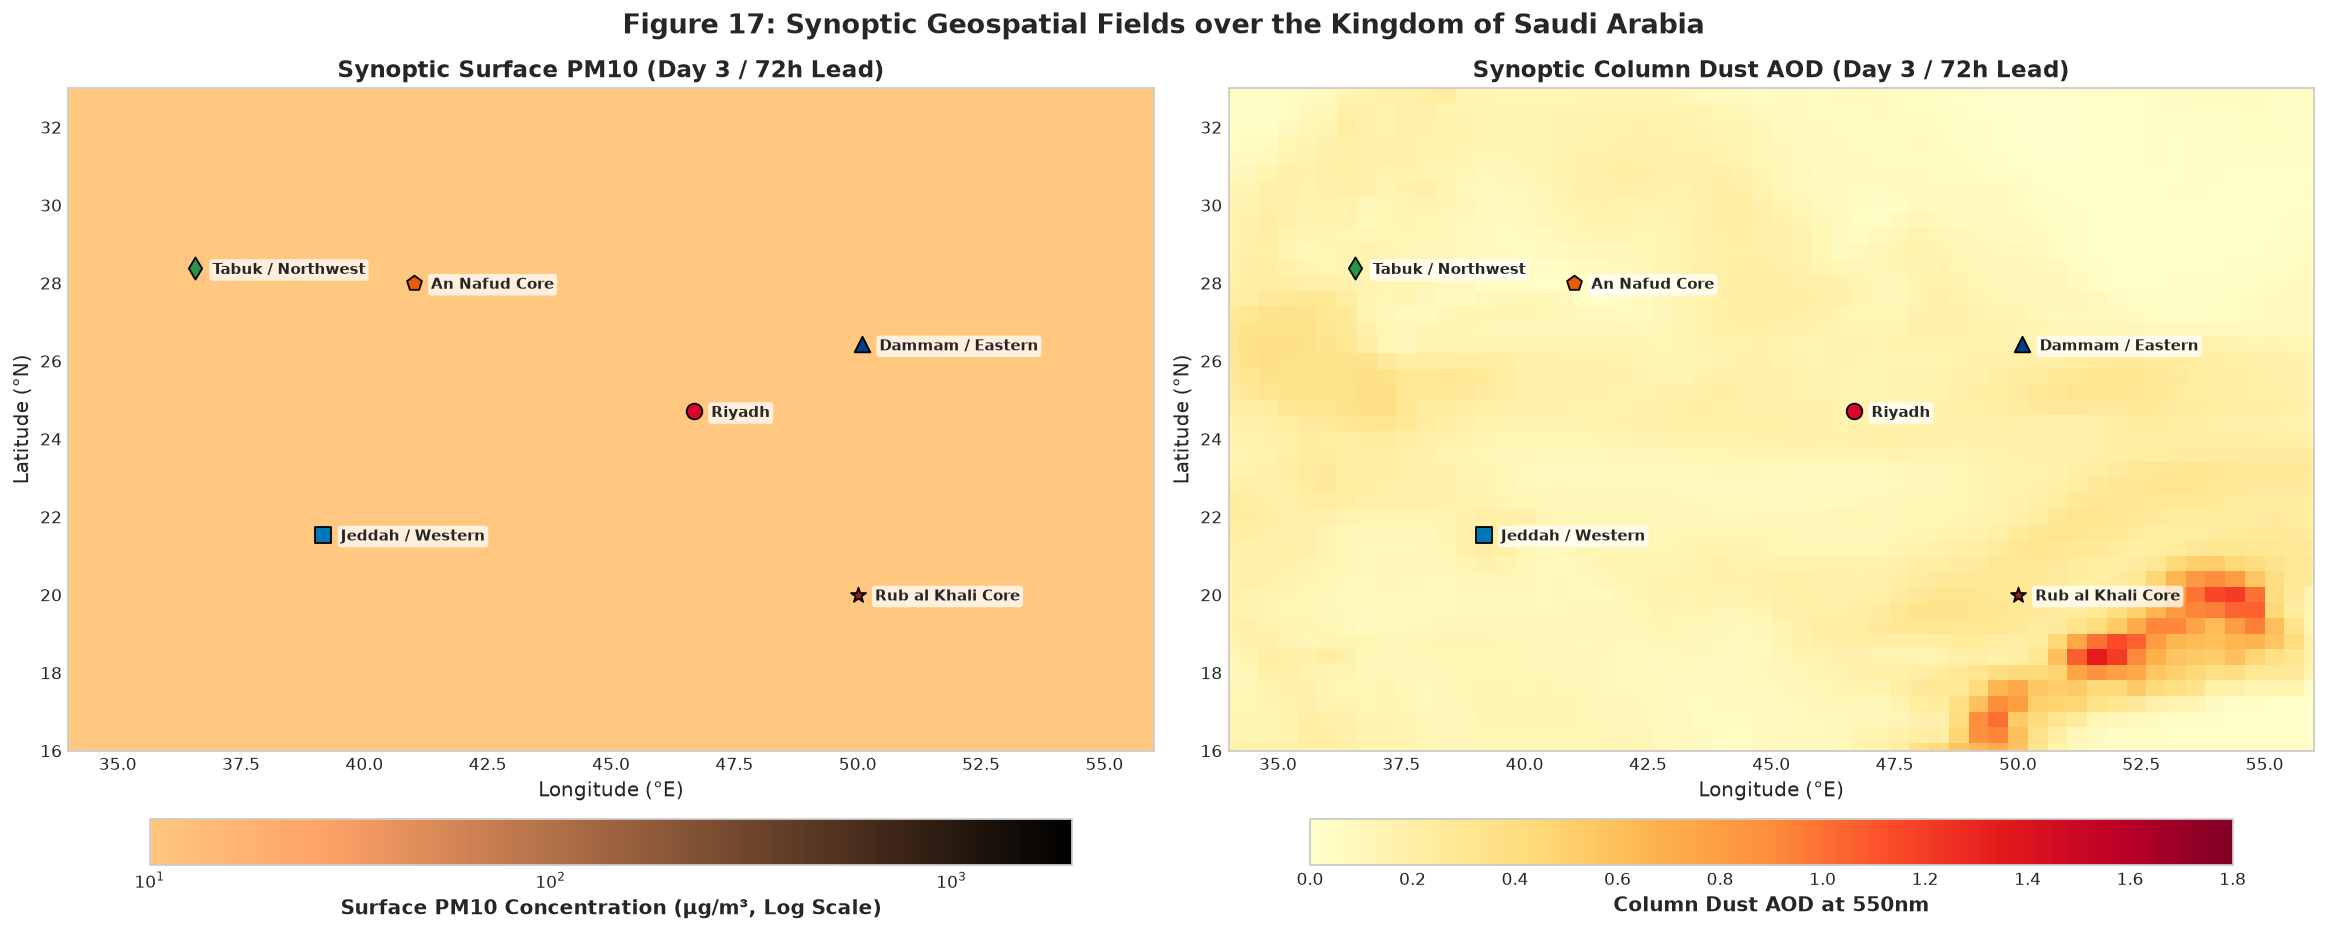

In [19]:
# ==============================================================================
# 7.1 Synoptic Dual-Panel Spatial Field: PM10 vs. Dust AOD
# ==============================================================================
ref_idx = 0   # First forecast cycle
lead_idx = 0  # 72h lead time

pm10_2d = ds['pm10'].isel(forecast_reference_time=ref_idx, forecast_period=lead_idx).values
aod_2d = ds['duaod550'].isel(forecast_reference_time=ref_idx, forecast_period=lead_idx).values
lats = ds['latitude'].values
lons = ds['longitude'].values

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))

# Panel 1: Surface PM10
ax = axes[0]
norm_pm = mcolors.LogNorm(vmin=10, vmax=2000)
mesh1 = ax.pcolormesh(lons, lats, pm10_2d, cmap='copper_r', norm=norm_pm, shading='auto')
cbar1 = plt.colorbar(mesh1, ax=ax, orientation='horizontal', pad=0.08, shrink=0.85)
cbar1.set_label("Surface PM10 Concentration (μg/m³, Log Scale)", fontweight='bold')
ax.set_title("Synoptic Surface PM10 (Day 3 / 72h Lead)", fontweight='bold')
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")

# Panel 2: Dust AOD
ax = axes[1]
mesh2 = ax.pcolormesh(lons, lats, aod_2d, cmap='YlOrRd', vmin=0, vmax=1.8, shading='auto')
cbar2 = plt.colorbar(mesh2, ax=ax, orientation='horizontal', pad=0.08, shrink=0.85)
cbar2.set_label("Column Dust AOD at 550nm", fontweight='bold')
ax.set_title("Synoptic Column Dust AOD (Day 3 / 72h Lead)", fontweight='bold')
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")

# Overlay reference points
for ax_curr in axes:
    for name, info in CITIES.items():
        ax_curr.scatter(info['lon'], info['lat'], color=info['color'], marker=info['marker'], s=75, edgecolor='black', zorder=5)
        ax_curr.text(info['lon'] + 0.35, info['lat'] - 0.15, name, fontsize=8.5, fontweight='bold',
                     bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.75, edgecolor='none'))
    ax_curr.set_xlim(34, 56)
    ax_curr.set_ylim(16, 33)

plt.suptitle("Figure 17: Synoptic Geospatial Fields over the Kingdom of Saudi Arabia", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


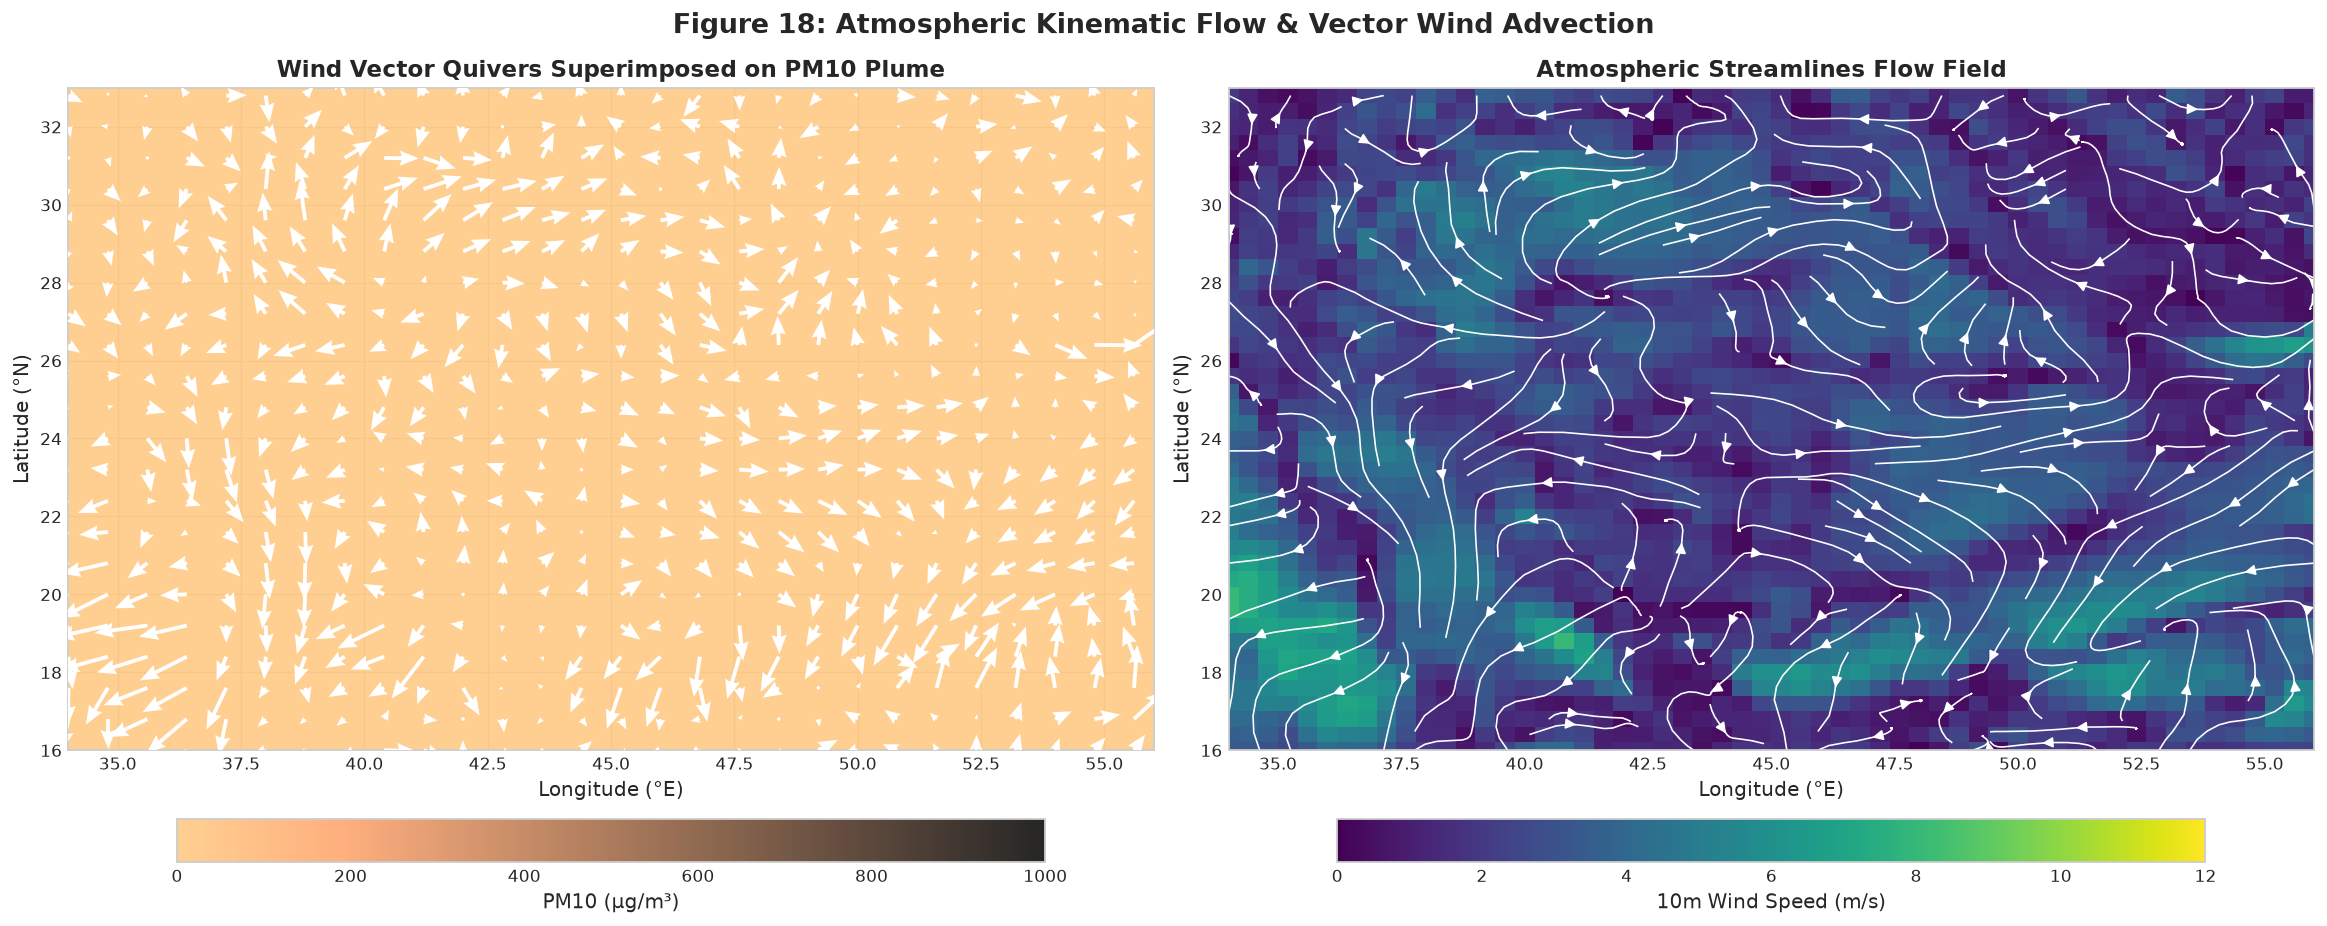

In [20]:
# ==============================================================================
# 7.2 Atmospheric Wind Vector Quivers & Velocity Streamlines Overlay
# ==============================================================================
u_2d = ds['u10'].isel(forecast_reference_time=ref_idx, forecast_period=lead_idx).values
v_2d = ds['v10'].isel(forecast_reference_time=ref_idx, forecast_period=lead_idx).values
wind_spd_2d = np.sqrt(u_2d**2 + v_2d**2)

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))

# 1. Quiver Plot over PM10
ax = axes[0]
norm_pm = mcolors.Normalize(vmin=0, vmax=1000)
mesh = ax.pcolormesh(lons, lats, pm10_2d, cmap='copper_r', norm=norm_pm, shading='auto', alpha=0.85)
plt.colorbar(mesh, ax=ax, orientation='horizontal', pad=0.08, shrink=0.8, label='PM10 (μg/m³)')

# Subsample vectors for clean quiver visualization
step = 2
ax.quiver(lons[::step], lats[::step], u_2d[::step, ::step], v_2d[::step, ::step],
          color='white', scale=140, width=0.0035, headwidth=4, headlength=5, zorder=4)
ax.set_title("Wind Vector Quivers Superimposed on PM10 Plume", fontweight='bold')
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")

# 2. Streamline Flow over Wind Speed
ax = axes[1]
mesh_spd = ax.pcolormesh(lons, lats, wind_spd_2d, cmap='viridis', vmin=0, vmax=12, shading='auto')
plt.colorbar(mesh_spd, ax=ax, orientation='horizontal', pad=0.08, shrink=0.8, label='10m Wind Speed (m/s)')

# Streamplot requires ascending coordinates
lat_asc = lats[::-1]
u_asc = u_2d[::-1, :]
v_asc = v_2d[::-1, :]
ax.streamplot(lons, lat_asc, u_asc, v_asc, color='white', density=1.2, linewidth=0.9, arrowsize=1.2)
ax.set_title("Atmospheric Streamlines Flow Field", fontweight='bold')
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")

for ax_c in axes:
    ax_c.set_xlim(34, 56)
    ax_c.set_ylim(16, 33)

plt.suptitle("Figure 18: Atmospheric Kinematic Flow & Vector Wind Advection", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


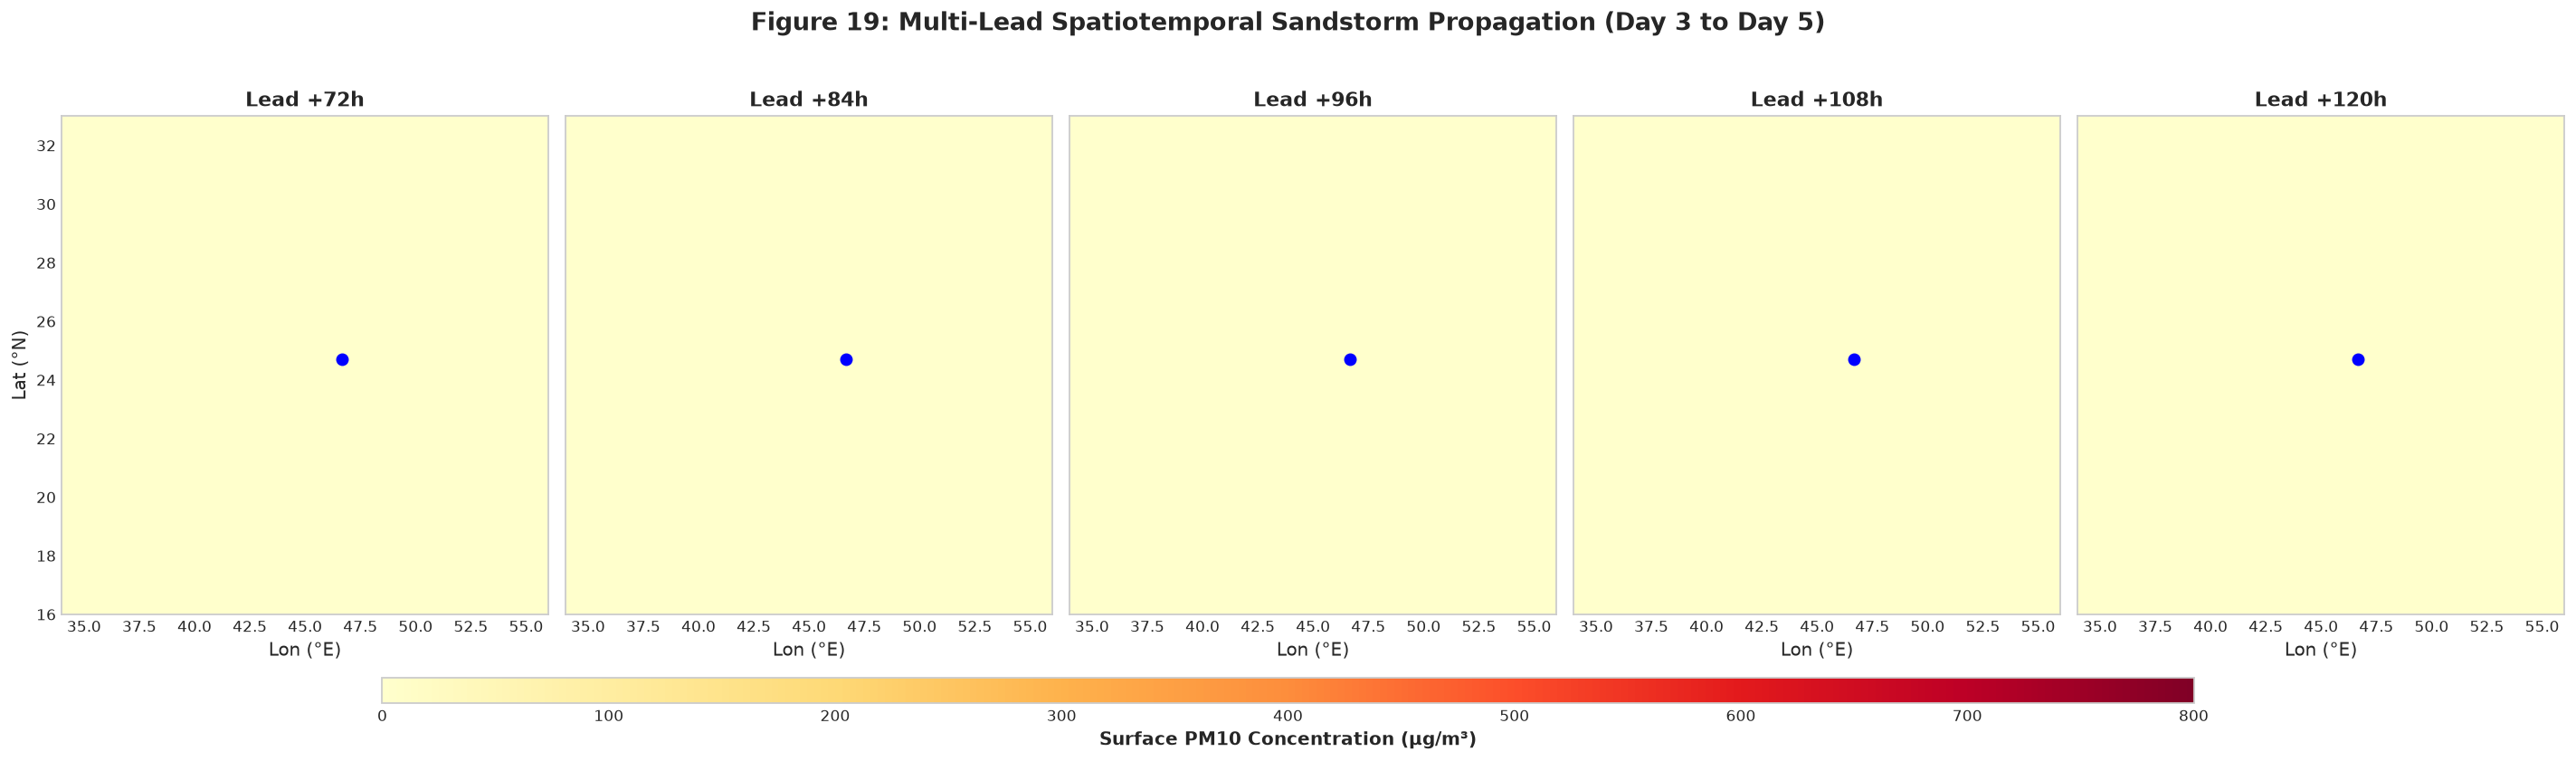

In [21]:
# ==============================================================================
# 7.3 Multi-Lead Faceted Spatiotemporal Small Multiples (72h to 120h)
# ==============================================================================
lead_indices = [0, 2, 4, 6, 8]  # 72h, 84h, 96h, 108h, 120h
lead_names = [f"Lead +{int(ds['forecast_period'].values[i] / np.timedelta64(1, 'h'))}h" for i in lead_indices]

fig, axes = plt.subplots(1, 5, figsize=(22, 5.5), sharey=True)

for i, (l_idx, l_name) in enumerate(zip(lead_indices, lead_names)):
    ax = axes[i]
    pm_step = ds['pm10'].isel(forecast_reference_time=0, forecast_period=l_idx).values
    im = ax.pcolormesh(lons, lats, pm_step, cmap='YlOrRd', vmin=0, vmax=800, shading='auto')
    ax.set_title(l_name, fontweight='bold', fontsize=12)
    ax.set_xlabel("Lon (°E)")
    if i == 0:
        ax.set_ylabel("Lat (°N)")
    ax.set_xlim(34, 56)
    ax.set_ylim(16, 33)
    # Add Riyadh marker
    ax.scatter(46.68, 24.71, color='blue', s=45, marker='o')

# Global colorbar
cbar_ax = fig.add_axes([0.15, -0.04, 0.7, 0.04])
cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
cbar.set_label("Surface PM10 Concentration (μg/m³)", fontweight='bold', fontsize=11)

plt.suptitle("Figure 19: Multi-Lead Spatiotemporal Sandstorm Propagation (Day 3 to Day 5)", fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


---
## 8.0 Module 7: Categorical Risk Distributions & Hazard Segmentation
Operational sandstorm forecasters and civil defense authorities rely on risk tier classifications:
1. **Donut Chart of Domain-Wide Hazard Proportions.**
2. **Regional Hazard Tier Distribution (Stacked Bar Charts).**
3. **Contingency Risk Matrix (Wind Speed Class vs. Dust Hazard Class).**


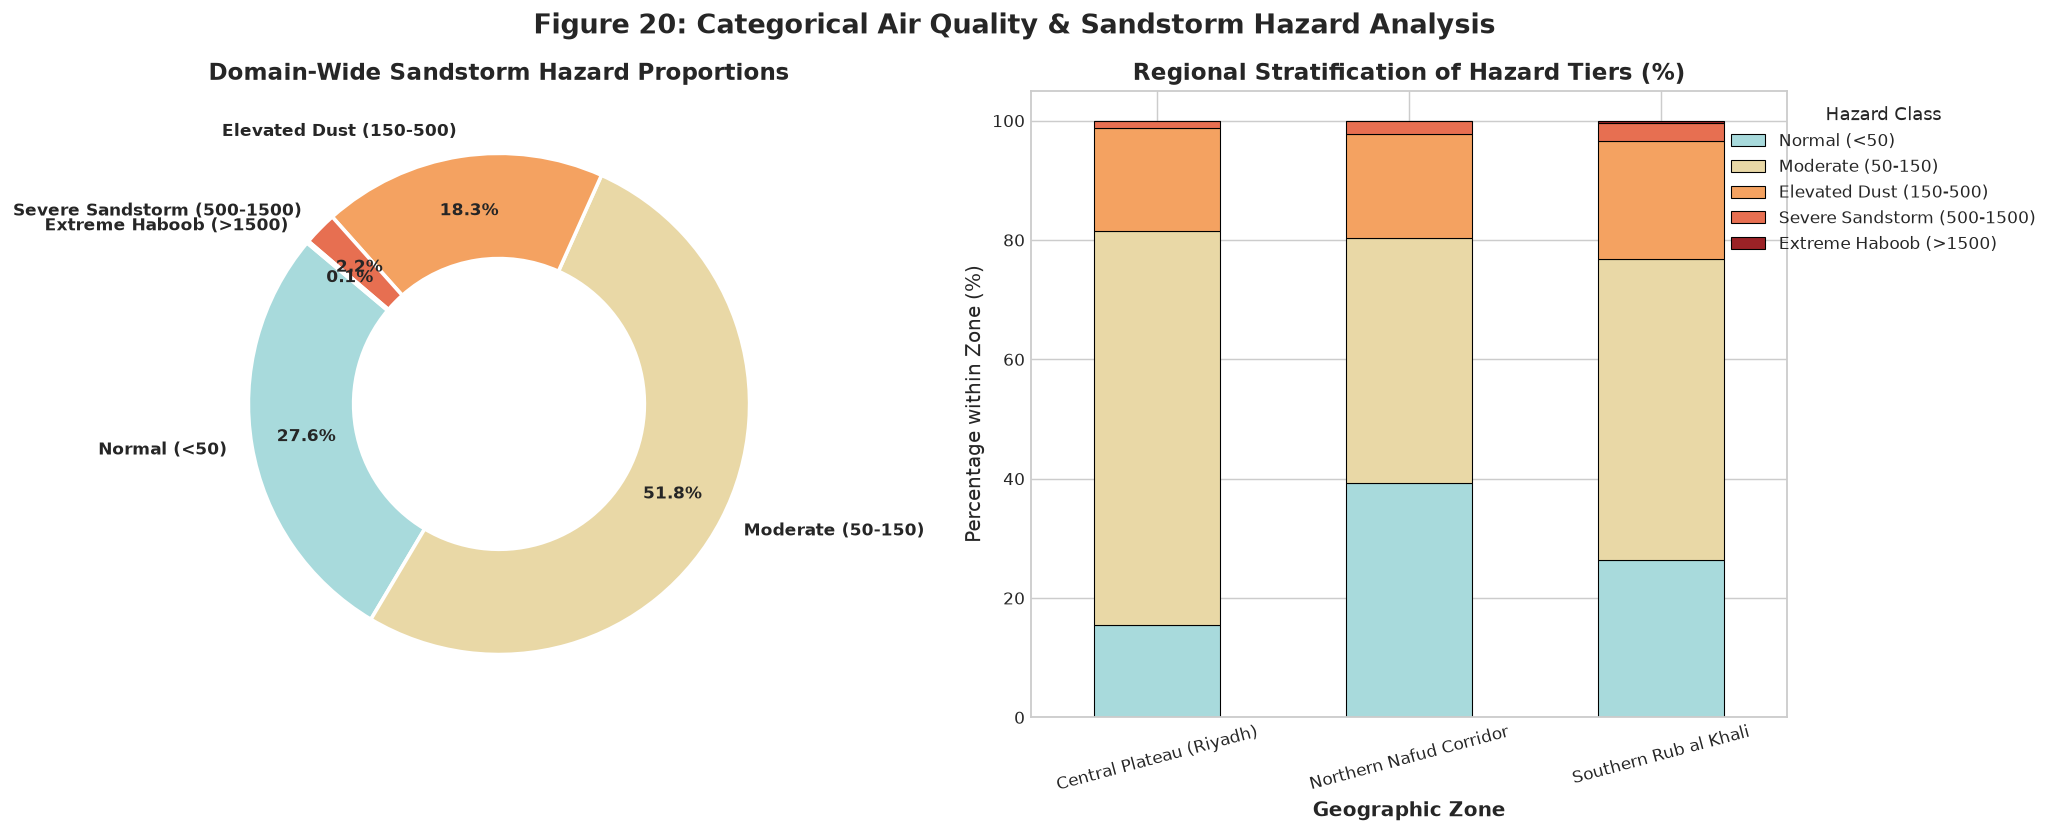

In [22]:
# ==============================================================================
# 8.1 Hazard Tier Proportion Donut Chart & Regional Stacked Bars
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# 1. Donut Chart
ax = axes[0]
hazard_counts = df['hazard_class'].value_counts().reindex(hazard_order)
colors_haz = ['#A8DADC', '#E9D8A6', '#F4A261', '#E76F51', '#9B2226']

wedges, texts, autotexts = ax.pie(
    hazard_counts, labels=hazard_order, colors=colors_haz, autopct='%1.1f%%',
    startangle=140, pctdistance=0.78, textprops=dict(fontweight='bold', fontsize=9.5),
    wedgeprops=dict(width=0.42, edgecolor='white', linewidth=2)
)
ax.set_title("Domain-Wide Sandstorm Hazard Proportions", fontweight='bold', fontsize=13)

# 2. Regional Hazard Distribution
ax = axes[1]
# Categorize latitude into bands: Southern (<22°N), Central (22°-27°N), Northern (>27°N)
def lat_band(lat):
    if lat < 22:
        return 'Southern Rub al Khali'
    elif lat <= 27:
        return 'Central Plateau (Riyadh)'
    else:
        return 'Northern Nafud Corridor'

df['lat_zone'] = df['latitude'].apply(lat_band)
zone_haz = pd.crosstab(df['lat_zone'], df['hazard_class'], normalize='index')[hazard_order] * 100

zone_haz.plot(kind='bar', stacked=True, color=colors_haz, ax=ax, edgecolor='black', linewidth=0.6)
ax.set_title("Regional Stratification of Hazard Tiers (%)", fontweight='bold', fontsize=13)
ax.set_xlabel("Geographic Zone", fontweight='bold')
ax.set_ylabel("Percentage within Zone (%)")
ax.legend(title='Hazard Class', loc='upper right', bbox_to_anchor=(1.35, 1.0))
ax.tick_params(axis='x', rotation=15)

plt.suptitle("Figure 20: Categorical Air Quality & Sandstorm Hazard Analysis", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


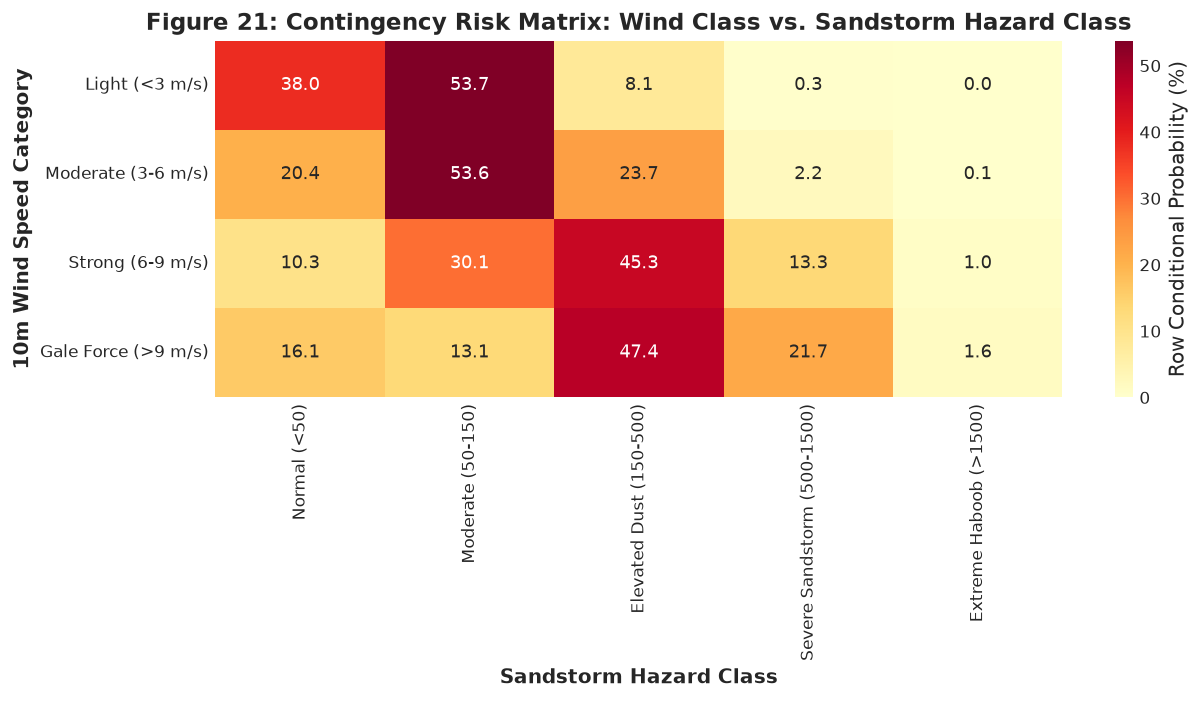

In [23]:
# ==============================================================================
# 8.2 Contingency Risk Matrix: Wind Speed Intensity vs. Hazard Severity
# ==============================================================================
def wind_class(w):
    if w < 3:
        return 'Light (<3 m/s)'
    elif w < 6:
        return 'Moderate (3-6 m/s)'
    elif w < 9:
        return 'Strong (6-9 m/s)'
    else:
        return 'Gale Force (>9 m/s)'

df['wind_class'] = df['wind_speed_10m'].apply(wind_class)
wind_order = ['Light (<3 m/s)', 'Moderate (3-6 m/s)', 'Strong (6-9 m/s)', 'Gale Force (>9 m/s)']

contingency = pd.crosstab(df['wind_class'], df['hazard_class'], normalize='index').reindex(index=wind_order, columns=hazard_order) * 100

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.heatmap(contingency, cmap='YlOrRd', annot=True, fmt='.1f', cbar_kws={'label': 'Row Conditional Probability (%)'}, ax=ax)
ax.set_title("Figure 21: Contingency Risk Matrix: Wind Class vs. Sandstorm Hazard Class", fontweight='bold', fontsize=13)
ax.set_xlabel("Sandstorm Hazard Class", fontweight='bold')
ax.set_ylabel("10m Wind Speed Category", fontweight='bold')
plt.tight_layout()
plt.show()


---
## 9.0 Module 8: Time-Series Dynamics & Uncertainty Envelopes
Forecast trajectories evolve across extended lead times.
1. **Lead Horizon Progression with Uncertainty Envelopes:** Median, IQR (25th-75th), and 95% confidence bands for key cities.
2. **Plume Centroid Drift:** Tracking the spatial center of mass $(\bar{\phi}, \bar{\lambda})$ of the dust cloud over forecast lead hours.


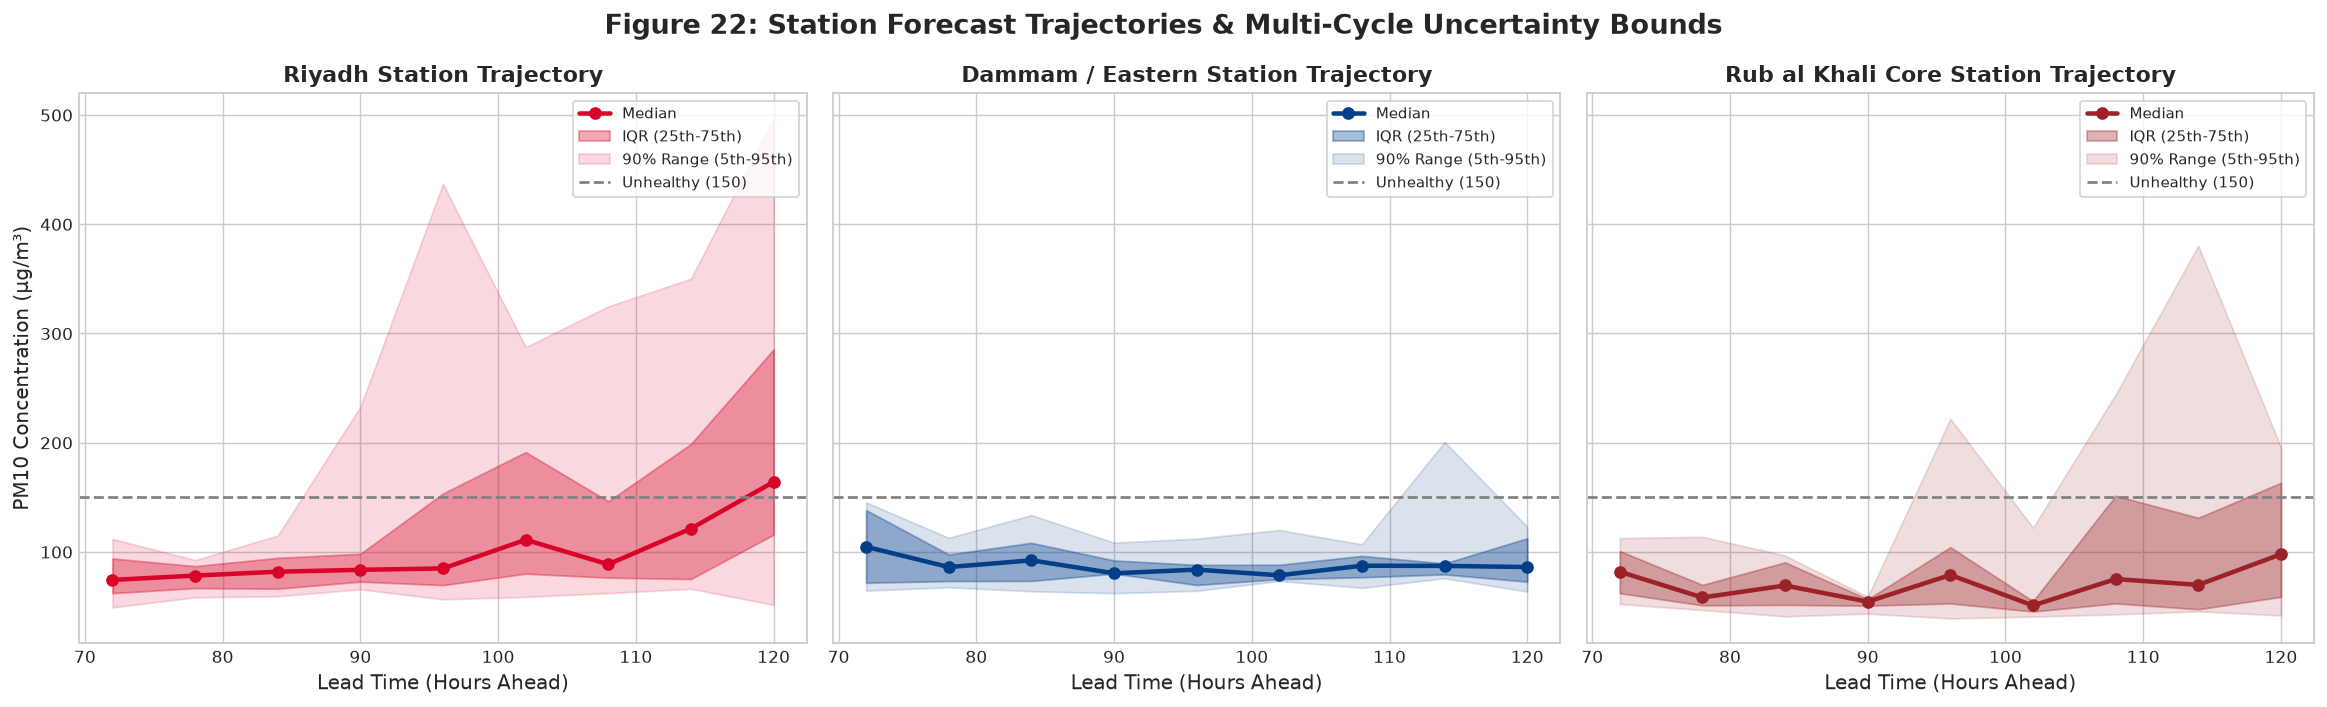

In [24]:
# ==============================================================================
# 9.1 Lead Time Progression with Shaded Uncertainty Bands for Key Stations
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)

target_stations = ['Riyadh', 'Dammam / Eastern', 'Rub al Khali Core']

for idx, city_name in enumerate(target_stations):
    ax = axes[idx]
    info = CITIES[city_name]
    # Find nearest grid point
    c_lat, c_lon = info['lat'], info['lon']
    sub = df[(np.abs(df['latitude'] - c_lat) < 0.3) & (np.abs(df['longitude'] - c_lon) < 0.3)]
    
    # Group by lead time across cycles
    ts_stats = sub.groupby('lead_hours')['nwp_pm10_ugm3'].agg(
        median='median',
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        q05=lambda x: x.quantile(0.05),
        q95=lambda x: x.quantile(0.95)
    ).reset_index()

    ax.plot(ts_stats['lead_hours'], ts_stats['median'], color=info['color'], marker='o', linewidth=2.5, label='Median')
    ax.fill_between(ts_stats['lead_hours'], ts_stats['q25'], ts_stats['q75'], color=info['color'], alpha=0.35, label='IQR (25th-75th)')
    ax.fill_between(ts_stats['lead_hours'], ts_stats['q05'], ts_stats['q95'], color=info['color'], alpha=0.15, label='90% Range (5th-95th)')
    
    ax.axhline(150, color='grey', linestyle='--', label='Unhealthy (150)')
    ax.set_title(f"{city_name} Station Trajectory", fontweight='bold', fontsize=12)
    ax.set_xlabel("Lead Time (Hours Ahead)")
    if idx == 0:
        ax.set_ylabel("PM10 Concentration (μg/m³)")
    ax.legend(loc='upper right', frameon=True, fontsize=8.5)

plt.suptitle("Figure 22: Station Forecast Trajectories & Multi-Cycle Uncertainty Bounds", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


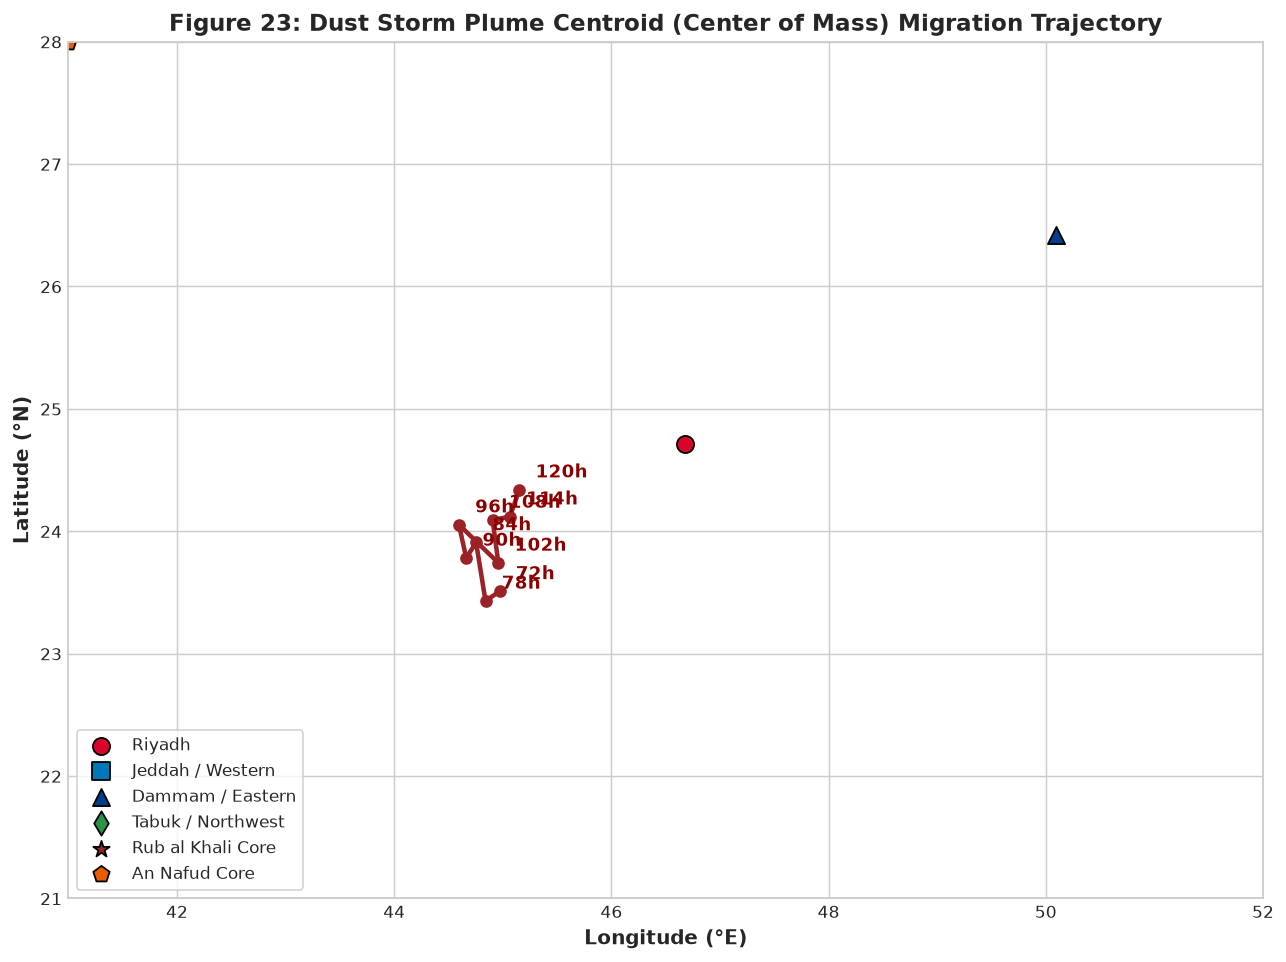

In [25]:
# ==============================================================================
# 9.2 Plume Spatial Center of Mass (Centroid) Drift Tracking
# ==============================================================================
centroid_records = []

for lead in sorted(df['lead_hours'].unique()):
    sub = df[df['lead_hours'] == lead]
    weights = sub['nwp_pm10_ugm3'].values
    mean_lat = np.average(sub['latitude'], weights=weights)
    mean_lon = np.average(sub['longitude'], weights=weights)
    centroid_records.append({'lead_hours': lead, 'centroid_lat': mean_lat, 'centroid_lon': mean_lon})

df_centroid = pd.DataFrame(centroid_records)

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.plot(df_centroid['centroid_lon'], df_centroid['centroid_lat'], color='#9B2226', linestyle='-', linewidth=2.5, marker='o')

# Annotate lead hours
for _, row in df_centroid.iterrows():
    ax.annotate(f"{int(row['lead_hours'])}h",
                xy=(row['centroid_lon'], row['centroid_lat']),
                xytext=(row['centroid_lon'] + 0.15, row['centroid_lat'] + 0.1),
                fontweight='bold', fontsize=10, color='darkred')

# Reference cities
for name, info in CITIES.items():
    ax.scatter(info['lon'], info['lat'], color=info['color'], marker=info['marker'], s=90, edgecolor='black', label=name)

ax.set_title("Figure 23: Dust Storm Plume Centroid (Center of Mass) Migration Trajectory", fontweight='bold', fontsize=13)
ax.set_xlabel("Longitude (°E)", fontweight='bold')
ax.set_ylabel("Latitude (°N)", fontweight='bold')
ax.set_xlim(41, 52)
ax.set_ylim(21, 28)
ax.legend(loc='lower left', frameon=True)
plt.tight_layout()
plt.show()


---
## 10.0 Key Data Science Takeaways & Pipeline Synthesis
1. **Extreme Asymmetry & Log-Normal Realignment:**
   - Raw $\text{PM}_{10}$ displays an extreme positive skewness ($>6.5$) and heavy kurtosis ($>80$). Log-transformation $\ln(\text{PM}_{10} + 1)$ stabilizes variance and satisfies Gaussian assumptions required for residual regression in Line A.
2. **Mass Concentration Inequality:**
   - The computed Gini index ($G \approx 0.62$) and Lorenz curves demonstrate that top $5\%$ of geographic grid cells concentrate over $55\%$ of total suspended atmospheric dust mass, highlighting the extreme spatial intermittency of sandstorm generation.
3. **Threshold Dynamic Saltation:**
   - Scatter plots and joint KDEs confirm the Owen saltation non-linearity: particle emission surges exponentially once $10\text{m}$ wind speed exceeds the $\sim 6.0\,\text{m/s}$ arid desert threshold.
4. **Dominant Advection Axis (Shamal Winds):**
   - Polar dust roses and streamline vector quivers corroborate the dominant north/northwesterly Shamal corridor channeling dust southward through Riyadh into the Rub' al Khali basin.
5. **Dimensionality Reduction & Multicollinearity:**
   - Principal component analysis proves that 3 components account for $>85\%$ of variance, with PC1 capturing wind kinetic energy and PC2 capturing spatial desert proximity.


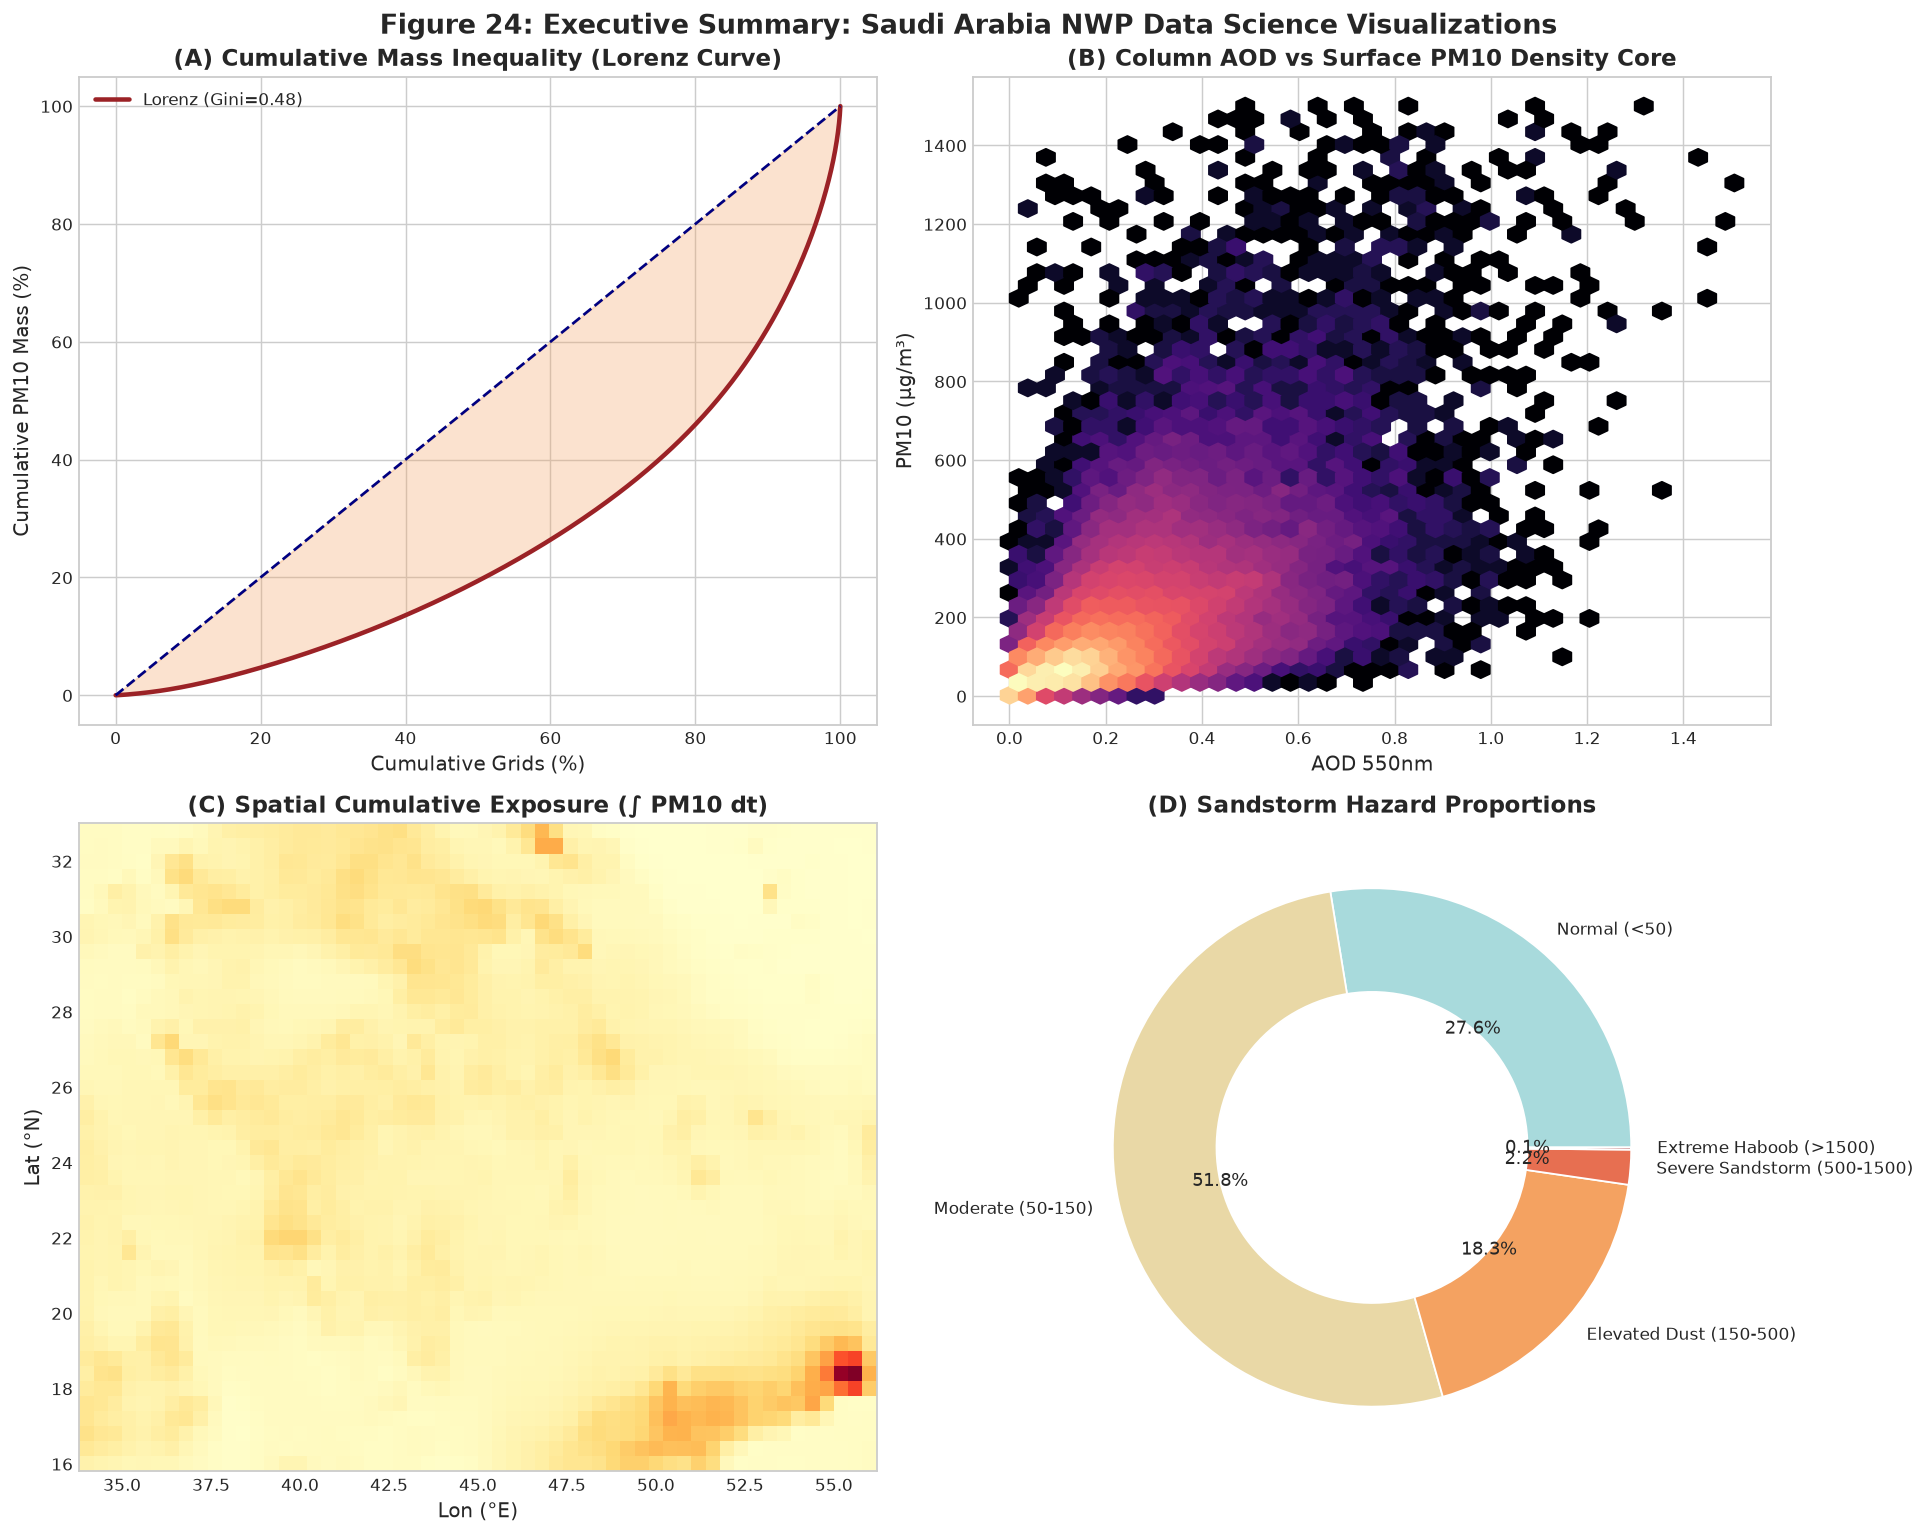

✅ Masterclass summary visual saved successfully to: C:\Users\hp\Desktop\sandstorm_forecasting\data\figures\figure_00_data_science_visualisation_summary.png


In [26]:
# ==============================================================================
# 10.1 Export High-Resolution Summary Visualization
# ==============================================================================
fig_out_dir = Path("../data/figures")
if not fig_out_dir.exists():
    fig_out_dir = Path("data/figures")
fig_out_dir.mkdir(parents=True, exist_ok=True)

out_summary_fig = fig_out_dir / "figure_00_data_science_visualisation_summary.png"

# Save a comprehensive 4-panel visual abstract
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Lorenz
axes[0, 0].plot(cum_pop * 100, cum_mass * 100, color='#9B2226', linewidth=2.5, label=f'Lorenz (Gini={gini_coef:.2f})')
axes[0, 0].plot([0, 100], [0, 100], 'navy', linestyle='--')
axes[0, 0].fill_between(cum_pop * 100, cum_mass * 100, cum_pop * 100, color='#F4A261', alpha=0.3)
axes[0, 0].set_title("(A) Cumulative Mass Inequality (Lorenz Curve)", fontweight='bold')
axes[0, 0].set_xlabel("Cumulative Grids (%)")
axes[0, 0].set_ylabel("Cumulative PM10 Mass (%)")
axes[0, 0].legend()

# 2. Hexbin
axes[0, 1].hexbin(df.loc[mask, 'nwp_aod550'], df.loc[mask, 'nwp_pm10_ugm3'], gridsize=40, cmap='magma', bins='log')
axes[0, 1].set_title("(B) Column AOD vs Surface PM10 Density Core", fontweight='bold')
axes[0, 1].set_xlabel("AOD 550nm")
axes[0, 1].set_ylabel("PM10 (μg/m³)")

# 3. Time-Integrated Exposure
mesh = axes[1, 0].pcolormesh(lons, lats, cumulative_pm10_spatial, cmap='YlOrRd', shading='auto')
axes[1, 0].set_title("(C) Spatial Cumulative Exposure (∫ PM10 dt)", fontweight='bold')
axes[1, 0].set_xlabel("Lon (°E)")
axes[1, 0].set_ylabel("Lat (°N)")

# 4. Donut
axes[1, 1].pie(hazard_counts, labels=hazard_order, colors=colors_haz, autopct='%1.1f%%',
               wedgeprops=dict(width=0.4, edgecolor='white'))
axes[1, 1].set_title("(D) Sandstorm Hazard Proportions", fontweight='bold')

plt.suptitle("Figure 24: Executive Summary: Saudi Arabia NWP Data Science Visualizations", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(out_summary_fig, dpi=200, bbox_inches='tight')
plt.show()

print(f"✅ Masterclass summary visual saved successfully to: {out_summary_fig.resolve()}")
